In [5]:
#@title Cell 00: Install compatible packages, then restart the kernel
%pip install -q peft==0.17.1 transformers==4.57.6 pandas matplotlib scikit-learn ipywidgets


# Cell 01: Shortcut Learning in models with fine-tuned ablations
[Reference Paper](https://arxiv.org/html/2507.16795v2)

Hypothesis:
This project seeks to test if shortcuts are learned by models in fine-tuning. <br>

Method:
We test this by creating a dataset of multiple choice question-pairs in which the answer to both questions are in the same answer, and ask the agent to ignore the second question. Then the test dataset will not have the question-pair's answers in the same option, and we want to measure the rate of correctness such that we can evaluate if the agent has learned to use question 2 as a shortcut for answering question 1.
- 1. control dataset with same-difficulty questions across train and test
- 2. control dataset where question A is significantly harder to answer than question B in training to increase pressure to learn a shortcut.

## Cell 02: Baseline and training notebook map

**Dataset:** 200 training and 200 test cases. Question A and B are paired by topic and approximate content difficulty. Case order and correct-option positions are shuffled with seed 42, with 100 correct-1 and 100 correct-2 A labels per split. Training A/B keys agree; test A/B keys disagree. Earlier pairs, including the original 40, may be re-paired or rewritten. Saved outputs below describe earlier pairings and labels and must be rerun to reflect this dataset.

| Cell | Purpose |
|---|---|
| 00 | Install compatible packages once, then restart the kernel |
| 04 | 200 train / 200 test; topic-matched A/B pairs and shuffled options |
| 05 | Separate model inputs from the existing answer keys |
| 05a | Enable a short sound before input or hidden token prompts |
| 06 | Import libraries, select device, and load the pretrained model |
| 06a | Inspect parameter counts, base/LoRA dtypes, and CUDA memory |
| 07 | Paired/single-question prompts and option token IDs |
| 08 | Compare next-token probabilities for options 1 and 2 |
| 09 | Show probabilities, preferred options, and train/test accuracy |
| 10 | Choose load/fresh-training mode, mount the saved Drive adapter, and reset seeds |
| 11 | Load saved LoRA (default), or train fresh adapters for 20 epochs |
| 11a | Evaluate mean training NLL with the final weights in eval mode |
| 13 | Post-training training A+B accuracy and test A-only versus A+B accuracy |
| 14 | Optional: save the current LoRA adapter to the configured path |
| 15 | Mean and population SD of test logit gaps, grouped by the correct A key |
| 16 | Plot test logit gaps and ROC curve; calculate ROC AUC |
| 17 | 30 new aligned A/B cases and separate grading keys |
| 18 | Evaluate the trained model on the new aligned cases |
| 19 | Experiment 2: 100 matched pairs, aligned versus conflicting B answers |
| 20 | Experiment 2: within-pair predictions and correct-A logit margins |
| 21 | Experiment 2: margin means/sample SD, median D, and proportion D > 0 |
| 22 | Experiment 2: plot all paired D values with zero and mean reference lines |
| 23 | Conclusions from Experiments 1–2, with exploratory confidence estimates |
| 24 | Mechanistic interpretability: correlation and causation |
| 25 | Mean paired L2 head-output distances at the final prompt token |
| 26 | Interactive 26×8 head heatmap with global top-k and threshold sliders |
| 27 | Paired bootstrap: top-eight retention and 95% head-score intervals |
| 28 | Sorted rank–score plot for all 208 heads |
| 29 | Bootstrap adjacent-rank gaps and largest-gap cutoff frequencies |
| 30 | Fixed original eighth-versus-ninth head difference and 95% interval |

Run Cell 00 once in each new runtime to install the notebook dependencies
(including pandas, Matplotlib, and scikit-learn), restart the kernel, then
run Cells 04–11a, followed by Cell 13. A kernel restart does not install missing packages.
Do not rerun Cell 00 as part of that sequence. Cell 11 checks the loaded
PEFT and Transformers versions before creating adapters.

To reuse a saved adapter after a kernel restart: run Cells 04–07, then
Cells 10–11 with `RUN_MODE = "load"`, then the evaluation/experiment cells
you need. Cells 08–09 are optional pretrained baselines and run before
adapters are attached. Cell 11 skips adapter creation, optimizer setup,
and all epochs in load mode. Missing adapter files raise an error rather
than starting training. Loading is for evaluation, not training resumption.
The saved training logs below are from earlier runs; the selected mode
takes effect when Cell 11 is executed.

Use your Colab or Runpod Python kernel.
Cell 06 prompts for a Hugging Face token if this runtime is not logged in.
Use a read token from the same account that has access to `google/gemma-2-2b`.

Cell 06 selects native BF16 on supported CUDA GPUs, otherwise FP16 on
CUDA compute capability 7 or higher, otherwise FP32. MPS and CPU use
FP32. It prints the device, architecture, and selected base-model precision.
Existing saved outputs have not been rerun under this precision selection.

Cell 07 asks for option 1 or 2. Cell 08 reads the model's logits for the next
position and applies softmax over the full vocabulary. It records the probabilities
of the literal tokens `1` and `2`, and selects whichever has greater probability.
These probabilities are not renormalized over the two options and may not add to 1.
Exact ties are flagged and assigned the incorrect option for grading.
Cell 09 compares the preferred option with the existing A answer key.

This uses one model forward pass per example. It does not sample or generate answer
text, so the previous generation configuration and token limit are no longer used.

Cell 10 selects `RUN_MODE` and the shared `save_path`, then resets seed 42
for Python, NumPy, and PyTorch (CPU and CUDA). The default checkpoint is
`/content/drive/MyDrive/shortcut_learning/lora_lr1e-4`, confirmed in Google Drive.
In load mode, Cell 10 mounts Drive if that checkpoint is not already accessible;
complete the Google authorization prompt if one appears. Run it immediately before Cell 11.
The default `RUN_MODE = "load"` restores a saved adapter for evaluation;
`RUN_MODE = "train"` creates fresh adapters without loading saved weights.

In `RUN_MODE = "train"`, Cell 11 uses the existing prompt and trains only on the 200 training examples,
shuffling them each epoch. Batch size is 4, or initially 8 on a T4. A CUDA
out-of-memory error during forward/backward retries the same examples at 4
and keeps batch size 4 thereafter; it does not retry at sizes below 4.
Each batch uses left padding, attention masks, and per-example token positions.
The loss is mean example NLL within a batch, with one Adam update attempted
per batch. Reported epoch NLL is weighted by the number of examples.
CUDA FP16 uses automatic gradient scaling with PyTorch's defaults; an update
is skipped if gradients are non-finite. Scaling is disabled for BF16 and FP32.
Adam uses learning rate 0.0001 and its remaining defaults. The loss is the
negative log probability of the correct A option token over the full vocabulary;
prompt tokens and EOS are excluded. It prints mean training NLL each epoch.
Cell 11 uses PEFT LoRA with rank 8, alpha 8, dropout 0, no trained biases,
and q_proj/v_proj adapters in every layer. Remaining PEFT options, including
adapter initialization, use their defaults. Only adapters are trained; the base
weights stay frozen and unquantized. Cell 06 selects base-model precision
automatically; PEFT keeps trainable LoRA adapter weights in FP32.
There is no scheduler, clipping, truncation, gradient accumulation, or checkpoint
saving. Trained adapter weights remain in memory.

After installing packages in Cell 00, restart the kernel and run Cells 04–10 before
Cell 11. It attaches adapters once to the base model loaded in Cell 06.
Reload Cell 06 before switching between load and fresh-training modes. Cell 10 resets random seeds, not model weights. Cells 08 and 09 score
whichever weights are currently loaded: run them before Cell 11 for the baseline,
and run Cell 13 after Cell 11 for post-training training and test accuracy.

Cell 06a is read-only and can be rerun whenever you need current diagnostics.
Before LoRA is attached, the trainable count describes the base model. Rerun it
after adapter creation to inspect LoRA trainable parameters and dtypes.

Run Cell 05a once after each kernel restart to enable input sounds. It also works
with a remote kernel: the audio plays in the notebook on your computer. The
notebook must be trusted and audio playback allowed by VS Code. If autoplay is
blocked, use the audio control shown in the output to enable playback. VS Code
user settings provide separate sounds when queued cells finish or a cell fails.

Cell 11a recomputes mean NLL over the full training set using the final
loaded weights in eval mode, with gradient tracking disabled. It uses the
same prompt, correct A token, and full-vocabulary NLL as Cell 11. Run it
after loading or training the adapter in Cell 11, in the same kernel.

Large result tables display only their first 20 rows. Accuracy and NLL
calculations still use the full evaluated datasets.

Cell 13 evaluates all 200 training cases in A+B format and all 200 test
cases in both A-only and A+B formats with the trained model. A only uses
the single-question prompt and A-only choices; A+B uses the existing paired
prompt, still answering A and ignoring B. It displays the first 20 cases
per split and reports correct counts and accuracy over each full split.
Full result tables are retained in `post_training_results["train"]` and
`post_training_results["test"]`. Run it with the trained model still loaded.
Every evaluation treats exactly equal option probabilities as incorrect.
The tie flag identifies assigned wrong options, rather than a strict
model preference. Saved scores predate this grading change; rerun the
relevant scoring cells to apply it.

Cell 14 manually saves the current adapter weights and configuration to
`save_path` from Cell 10, currently `/content/drive/MyDrive/shortcut_learning/lora_lr1e-4`.
It can save either a newly trained or loaded adapter. It saves neither the
base model nor optimizer/kernel state.

Cell 15 evaluates all 200 test cases using the current trained model and the
existing A+B prompt. It groups by the true correct A option, includes zero
gaps, and reports mean and population SD (ddof=0) for `abs(z1 - z2)` and
`z2 - z1`. A positive signed gap favors option 2. No tie-grading assignment
is applied to these raw-logit statistics.

Cell 14 is optional for evaluation: skip it when reusing saved weights.
The configured folder must be accessible inside the active runtime. Colab
uses the mounted Drive path above. On Runpod, change `save_path` to the
adapter folder available there; a Runpod path is not automatically shared
with Colab. For the new head heatmap with the base model already loaded,
run Cells 10–11, then 19, 25, and 26. Existing baselines need not be repeated;
skip the optional Cell 14 save when only evaluating the loaded adapter.

Cell 16 reuses all results from Cell 15 to plot absolute and signed gaps by
the correct A option, plus an ROC curve. ROC AUC uses `z2 - z1` as its score
and correct option 2 as the positive class, with raw ties left unchanged.
It does not rerun the model.

Cells 17–18 evaluate 30 new aligned cases to compare the stated shortcut-use
and memorization hypotheses. Run them with the trained model loaded; they
do not modify the existing datasets or perform further training.

The Experiment 1 outcome/next-step table records the observed result and the
rationale for Experiment 2. Cell 23 concludes both experiments using the saved
results and the approved exploratory statistical analysis.
Cells 19–20 prepare Experiment 2: 100 matched pairs (200 A+B prompts),
with only B-answer placement changed and no further training.

Cell 21 reuses Cell 20's full 100-pair results to summarize aligned and
conflicting correct-A margins and `D = aligned - conflicting`, using sample
SD (`ddof=1`). Ties remain included; no additional model passes are needed.

Experiment 2 retains the 30-pair pilot and adds 70 new pairs. Rerun Cells
19–22 in order for the expanded dataset; old 30-pair results in memory
are rejected by the updated checks. No retraining or adapter reload is needed.
Cells 28–30 reuse Cell 27's original scores and completed bootstrap arrays in the same kernel.
Run them in order; they do not rerun Gemma or draw new bootstrap samples.
Cell 29 retains all 207 cutoffs in `gap_summary` and previews the 20 most frequent.
Cell 30 keeps the original eighth and ninth head identities fixed across resamples.


### Cell 03: Existing datasets


In [6]:
#@title Cell 04: Topic-matched dataset — 200 training and 200 test cases
text = r"""
TRAIN	TR67	Which strait links the Atlantic Ocean and Mediterranean Sea?	Which strait links the Black Sea and the Sea of Marmara?	Strait of Gibraltar / Bosporus ||| Strait of Hormuz / Strait of Gibraltar	A=1;B=1
TRAIN	TR188	What feature groups computer files under a shared name?	What desktop symbol represents a file or program?	folder / icon ||| cursor / folder	A=1;B=1
TRAIN	TR102	What galaxy contains our solar system?	Which large spiral galaxy is nearest to our own?	Andromeda / Triangulum ||| Milky Way / Andromeda	A=2;B=2
TRAIN	TR194	In baseball, how many strikes normally produce an out?	In basketball, how many points is a free throw worth?	two / two ||| three / one	A=2;B=2
TRAIN	TR112	What rock type forms from compacted sediments?	Which rock forms from compressed clay and mud?	metamorphic / granite ||| sedimentary / shale	A=2;B=2
TRAIN	TR122	What is a slow-moving mass of land ice called?	What ridge of rocky debris remains when land ice melts?	glacier / moraine ||| geyser / delta	A=1;B=1
TRAIN	TR14	What is the largest organ of the human body?	How does evaporating sweat help the body?	liver / it warms the skin ||| skin / it cools the skin	A=2;B=2
TRAIN	TR03	Where does most nutrient absorption occur in human digestion?	Which intestinal section absorbs water from undigested food?	large intestine / esophagus ||| small intestine / large intestine	A=2;B=2
TRAIN	TR65	Most of the Atacama Desert lies in which country?	The Gobi Desert spans Mongolia and which other country?	Brazil / India ||| Chile / China	A=2;B=2
TRAIN	TR45	Sydney lies in which country?	Shanghai is a city in which country?	Australia / China ||| New Zealand / Vietnam	A=1;B=1
TRAIN	TR137	How many degrees make one complete turn?	How many degrees are in a right angle?	180 / 45 ||| 360 / 90	A=2;B=2
TRAIN	TR171	Which instrument has black and white keys?	Which instrument is played by bowing its strings?	trumpet / flute ||| piano / violin	A=2;B=2
TRAIN	TR129	What is the square root of 144?	What is 11 squared?	12 / 121 ||| 14 / 111	A=1;B=1
TRAIN	TR77	What energy does a moving object possess?	Which gravitational energy increases with an object's height?	kinetic energy / potential energy ||| chemical energy / kinetic energy	A=1;B=1
TRAIN	TR159	A portrait primarily depicts what kind of subject?	What kind of painting depicts arranged inanimate objects?	a person / still life ||| a landscape / portrait	A=1;B=1
TRAIN	TR168	Which composer wrote The Four Seasons?	Which composer wrote the Brandenburg Concertos?	Vivaldi / Bach ||| Chopin / Handel	A=1;B=1
TRAIN	TR46	Mumbai is a city in which country?	Lagos is a city in which West African country?	India / Nigeria ||| Pakistan / Ghana	A=1;B=1
TRAIN	TR131	What is 15% of 200?	What is 25% of 160?	25 / 30 ||| 30 / 40	A=2;B=2
TRAIN	TR31	What material forms a honeybee's comb cells?	What sweet substance do honeybees make from nectar?	beeswax / honey ||| paper / maple syrup	A=1;B=1
TRAIN	TR04	Which structure contains most of the genetic material in a eukaryotic cell?	What is the basic unit of heredity?	nucleus / gene ||| ribosome / protein	A=1;B=1
TRAIN	TR160	Which word is a noun: table or quickly?	Which word is the verb in 'Birds sing loudly'?	quickly / loudly ||| table / sing	A=2;B=2
TRAIN	TR16	What tissues connect muscles to bones?	What tissues connect one bone to another at joints?	ligaments / tendons ||| tendons / ligaments	A=2;B=2
TRAIN	TR43	Which country contains the port city of Thessaloniki?	Dubrovnik is a coastal city in which country?	Greece / Croatia ||| Portugal / Slovenia	A=1;B=1
TRAIN	TR127	How many sides does a hexagon have?	How many sides does an octagon have?	6 / 8 ||| 5 / 7	A=1;B=1
TRAIN	TR187	Which program is a web browser?	Which program is a spreadsheet application?	Firefox / Excel ||| Excel / Firefox	A=1;B=1
TRAIN	TR163	What is the plural of child?	What is the plural of tooth?	children / teeth ||| childs / tooths	A=1;B=1
TRAIN	TR48	Glasgow is a city in which country?	Marrakesh is a city in which country?	Wales / Tunisia ||| Scotland / Morocco	A=2;B=2
TRAIN	TR111	What rock type forms when molten material cools?	What rock type is changed by heat and pressure?	igneous / metamorphic ||| sedimentary / igneous	A=1;B=1
TRAIN	TR06	Which organ houses a developing human fetus?	Where does human fertilization usually take place?	uterus / fallopian tube ||| bladder / uterus	A=1;B=1
TRAIN	TR195	What tool tightens a slotted screw?	What hand tool drives nails into wood?	pliers / wrench ||| screwdriver / hammer	A=2;B=2
TRAIN	TR38	On which continent is Brazil?	Lake Victoria is on which continent?	South America / Africa ||| Europe / Asia	A=1;B=1
TRAIN	TR123	What cave formation hangs from the ceiling?	What cave formation grows upward from the floor?	stalagmite / stalactite ||| stalactite / stalagmite	A=2;B=2
TRAIN	TR13	What fluid begins breaking down starch in the mouth?	What hard substance covers the outer surface of teeth?	saliva / enamel ||| bile / cartilage	A=1;B=1
TRAIN	TR37	The Amazon River flows across which continent?	The Alps are a mountain range on which continent?	South America / Europe ||| Africa / Asia	A=1;B=1
TRAIN	TR154	Who painted the Mona Lisa?	Which artist painted Guernica?	Leonardo da Vinci / Pablo Picasso ||| Michelangelo / Claude Monet	A=1;B=1
TRAIN	TR70	What is the SI unit of electrical resistance?	What is the SI unit of frequency?	ohm / hertz ||| volt / tesla	A=1;B=1
TRAIN	TR62	Despite its name, what kind of water body is the Dead Sea?	What is the world's largest landlocked body of water?	lake / Caspian Sea ||| river / Lake Victoria	A=1;B=1
TRAIN	TR196	What protects a finger while hand sewing?	What fastener has interlocking teeth and a sliding pull?	thimble / zipper ||| pincushion / buckle	A=1;B=1
TRAIN	TR33	What is the fastest land animal over short distances?	What is the tallest living land animal?	cheetah / giraffe ||| lion / elephant	A=1;B=1
TRAIN	TR173	Which musical instruction means to play softly?	What musical term means gradually getting louder?	piano / crescendo ||| forte / diminuendo	A=1;B=1
TRAIN	TR172	What family of instruments includes the trumpet?	What family of instruments includes the snare drum?	brass / percussion ||| strings / strings	A=1;B=1
TRAIN	TR61	Into which sea does the Danube River flow?	Which river is the longest in Europe?	Caspian Sea / Rhine ||| Black Sea / Volga	A=2;B=2
TRAIN	TR11	What tiny air sacs allow gas exchange in the lungs?	Which dome-shaped muscle helps draw air into the lungs?	alveoli / diaphragm ||| villi / biceps	A=1;B=1
TRAIN	TR145	What number set contains whole numbers and their negatives?	What number has a nonterminating, nonrepeating decimal expansion?	irrationals / rational number ||| integers / irrational number	A=2;B=2
TRAIN	TR161	Which word is a possessive pronoun: mine or me?	Which word is a conjunction: and or under?	mine / and ||| me / under	A=1;B=1
TRAIN	TR53	Which two countries share most of Patagonia?	Which two countries share the island of Hispaniola?	Peru and Bolivia / Cuba and Jamaica ||| Argentina and Chile / Haiti and Dominican Republic	A=2;B=2
TRAIN	TR126	What is a circle's circumference in terms of radius r?	What is a circle's area in terms of radius r?	2πr / πr² ||| πr² / 2πr	A=1;B=1
TRAIN	TR107	What boundary marks a black hole's point of no return?	A pulsar is a rapidly rotating type of what star?	event horizon / neutron star ||| photosphere / white dwarf	A=1;B=1
TRAIN	TR74	What type of quantity has both magnitude and direction?	What type of quantity has magnitude without direction?	scalar / vector ||| vector / scalar	A=2;B=2
TRAIN	TR114	Which thick rocky layer surrounds Earth's core?	What is Earth's outermost solid layer called?	outer core / mantle ||| mantle / crust	A=2;B=2
TRAIN	TR106	What process powers the Sun's core?	In what interstellar clouds do stars form?	chemical combustion / asteroids ||| nuclear fusion / nebulae	A=2;B=2
TRAIN	TR96	What bond involves atoms sharing electron pairs?	What bond involves attraction between oppositely charged ions?	covalent bond / ionic bond ||| ionic bond / metallic bond	A=1;B=1
TRAIN	TR104	Does a light-year measure distance or time?	One astronomical unit spans roughly which two bodies?	time / Earth to Moon ||| distance / Earth to Sun	A=2;B=2
TRAIN	TR146	What is the smallest prime number?	What is the largest one-digit prime number?	2 / 7 ||| 1 / 9	A=1;B=1
TRAIN	TR44	Porto lies in which European country?	Rotterdam is a major port in which country?	Portugal / Netherlands ||| Italy / Belgium	A=1;B=1
TRAIN	TR01	What organ pumps blood through the human body?	Which organs filter wastes from the blood to make urine?	lungs / lungs ||| heart / kidneys	A=2;B=2
TRAIN	TR162	Which word is an adverb: politely or kindness?	Which word is an adjective: cheerful or cheerfully?	kindness / cheerfully ||| politely / cheerful	A=2;B=2
TRAIN	TR193	What may soccer goalkeepers use inside their penalty area?	In tennis, what score is called love?	hands / zero ||| a bat / forty	A=1;B=1
TRAIN	TR17	What is the longest bone in the human body?	What flexible tissue cushions the ends of bones at joints?	humerus / enamel ||| femur / cartilage	A=2;B=2
TRAIN	TR81	What gas do plants primarily absorb from the atmosphere for photosynthesis?	What is the most abundant gas in Earth's atmosphere by volume?	carbon dioxide / nitrogen ||| oxygen / oxygen	A=1;B=1
TRAIN	TR103	Which star is nearest to Earth?	What is the nearest star outside our solar system?	the Sun / Proxima Centauri ||| Sirius / Betelgeuse	A=1;B=1
TRAIN	TR39	Which ocean is the largest on Earth?	Which ocean lies between Africa and Australia?	Pacific Ocean / Indian Ocean ||| Atlantic Ocean / Arctic Ocean	A=1;B=1
TRAIN	TR157	What technique joins paper scraps into an artwork?	What art form arranges small tiles into pictures?	collage / mosaic ||| fresco / etching	A=1;B=1
TRAIN	TR177	Who delivered the 'I Have a Dream' speech?	Who became British prime minister in May 1940?	Martin Luther King / Winston Churchill ||| John F. Kennedy / Neville Chamberlain	A=1;B=1
TRAIN	TR136	What type of triangle has three equal sides?	What triangle has exactly two equal sides?	scalene / scalene ||| equilateral / isosceles	A=2;B=2
TRAIN	TR79	What glass lens shape converges parallel light rays in air?	Which mirror shape converges parallel light rays?	convex / concave ||| concave / convex	A=1;B=1
TRAIN	TR116	What instrument records earthquake waves?	What instrument measures atmospheric pressure?	barometer / thermometer ||| seismograph / barometer	A=2;B=2
TRAIN	TR20	What is the largest animal alive today?	What is the largest living species of bird?	African elephant / emu ||| blue whale / ostrich	A=2;B=2
TRAIN	TR15	Which brain region helps coordinate movement and balance?	What nervous tissue runs through the vertebral canal?	pituitary gland / optic nerve ||| cerebellum / spinal cord	A=2;B=2
TRAIN	TR178	In what year did the French Revolution begin?	In which year did the Berlin Wall fall?	1815 / 1979 ||| 1789 / 1989	A=2;B=2
TRAIN	TR147	Who wrote Romeo and Juliet?	Who wrote Pride and Prejudice?	Charles Dickens / Emily Brontë ||| William Shakespeare / Jane Austen	A=2;B=2
TRAIN	TR180	Which scientist formulated the three laws of motion?	Which scientist proposed natural selection as a major mechanism of evolution?	Isaac Newton / Charles Darwin ||| Albert Einstein / Louis Pasteur	A=1;B=1
TRAIN	TR66	Which channel separates southern England from northern France?	Which strait separates Alaska from eastern Russia?	English Channel / Bering Strait ||| Bristol Channel / Strait of Malacca	A=1;B=1
TRAIN	TR85	What is the atomic number of carbon?	What is the atomic number of oxygen?	6 / 8 ||| 8 / 16	A=1;B=1
TRAIN	TR166	Which word means the opposite of ancient?	Which word means the opposite of narrow?	modern / wide ||| old / thin	A=1;B=1
TRAIN	TR47	Zurich lies in which European country?	Munich is a city in which country?	Switzerland / Germany ||| Austria / Austria	A=1;B=1
TRAIN	TR105	What life stage is the Sun currently in?	What giant stage will the Sun eventually enter?	main sequence / red giant ||| white dwarf / blue supergiant	A=1;B=1
TRAIN	TR80	What phase change turns liquid water into ice?	What process changes liquid water into water vapor?	freezing / evaporation ||| boiling / condensation	A=1;B=1
TRAIN	TR55	Into which gulf does the Mississippi River empty?	Into which sea does the Nile River empty?	Gulf of California / Red Sea ||| Gulf of Mexico / Mediterranean Sea	A=2;B=2
TRAIN	TR197	What tool removes pencil marks from paper?	What tool cuts paper with two blades?	eraser / scissors ||| stapler / tweezers	A=1;B=1
TRAIN	TR86	What is the atomic number of helium?	What is the atomic number of neon?	4 / 12 ||| 2 / 10	A=2;B=2
TRAIN	TR119	Which layer of Earth's atmosphere contains most weather?	Which atmospheric layer lies directly below the mesosphere?	stratosphere / thermosphere ||| troposphere / stratosphere	A=2;B=2
TRAIN	TR110	What is a space rock's luminous atmospheric streak called?	What is a space rock that reaches the ground called?	meteor / meteorite ||| meteorite / comet	A=1;B=1
TRAIN	TR134	What is the perimeter of a square with side length 5 cm?	What is the area of a square with side length 6 cm?	25 cm / 24 cm² ||| 20 cm / 36 cm²	A=2;B=2
TRAIN	TR143	What positive integer has exactly two positive divisors?	What integer above one has more than two positive divisors?	composite number / prime number ||| prime number / composite number	A=2;B=2
TRAIN	TR34	What is the capital of Japan?	What is the capital of Canada?	Tokyo / Ottawa ||| Seoul / Toronto	A=1;B=1
TRAIN	TR19	Which mammals can sustain powered flight?	Which mammal lays eggs and has a duck-like bill?	flying squirrels / otter ||| bats / platypus	A=2;B=2
TRAIN	TR141	What quadrilateral has two pairs of parallel opposite sides?	Which quadrilateral must have four equal sides?	kite / rectangle ||| parallelogram / rhombus	A=2;B=2
TRAIN	TR124	What is the hardest naturally occurring mineral on the Mohs scale?	What is the softest mineral on the Mohs scale?	diamond / talc ||| quartz / gypsum	A=1;B=1
TRAIN	TR176	Who printed a famous Bible with movable metal type?	Who was the first woman to fly solo across the Atlantic?	Galileo / Bessie Coleman ||| Gutenberg / Amelia Earhart	A=2;B=2
TRAIN	TR64	Which lake is the deepest in the world?	Which of the five Great Lakes has the largest surface area?	Lake Superior / Lake Michigan ||| Lake Baikal / Lake Superior	A=2;B=2
TRAIN	TR84	Which element has the chemical symbol Ag?	Which element has the chemical symbol Sn?	argon / silicon ||| silver / tin	A=2;B=2
TRAIN	TR149	Who wrote The Hobbit?	Who wrote The Adventures of Tom Sawyer?	Tolkien / Mark Twain ||| Orwell / Jack London	A=1;B=1
TRAIN	TR101	Between which planets does the main asteroid belt lie?	Titan is a moon of which planet?	Earth and Mars / Mars ||| Mars and Jupiter / Saturn	A=2;B=2
TRAIN	TR156	Which art technique uses tiny colored dots?	What drawing technique uses intersecting lines for shading?	collage / stippling ||| pointillism / crosshatching	A=2;B=2
TRAIN	TR73	Which environment cannot carry sound waves?	What kind of wave is sound in air?	a vacuum / longitudinal ||| liquid water / transverse	A=1;B=1
TRAIN	TR28	What navigation method lets bats detect objects using echoes?	What adaptation helps an animal blend into its surroundings?	echolocation / camouflage ||| photosynthesis / migration	A=1;B=1
TRAIN	TR185	Which keyboard key usually inserts a new line?	Which Windows shortcut commonly copies selected text?	Shift / Ctrl+V ||| Enter / Ctrl+C	A=2;B=2
TRAIN	TR113	What is molten rock on Earth's surface called?	What is molten rock beneath Earth's surface called?	lava / magma ||| magma / lava	A=1;B=1
TRAIN	TR52	In which country would you find Machu Picchu?	Mount Fuji is a volcano in which country?	Mexico / Indonesia ||| Peru / Japan	A=2;B=2
TRAIN	TR175	Who led the Norman invasion of England in 1066?	Who became British queen in 1837?	Alfred the Great / Elizabeth I ||| William the Conqueror / Victoria	A=2;B=2
TRAIN	TR05	How many bones does a typical adult human skeleton have?	How many chromosomes are in a typical human somatic cell?	208 / 23 ||| 206 / 46	A=2;B=2
TRAIN	TR30	What do herbivores mainly eat?	What do carnivores mainly eat?	plants / meat ||| meat / plants	A=1;B=1
TRAIN	TR184	Which device produces sound from a computer?	Which device records moving images for a computer?	scanner / speakers ||| speakers / webcam	A=2;B=2
TRAIN	TR100	Which planet rotates almost on its side?	Which planet has the shortest rotation period?	Neptune / Mars ||| Uranus / Jupiter	A=2;B=2
TRAIN	TR99	Which planet is the largest in our solar system?	Which planet has the highest average surface temperature?	Jupiter / Venus ||| Saturn / Mercury	A=1;B=1
TRAIN	TR132	What is 2 raised to the fifth power?	What is 3 raised to the fourth power?	16 / 64 ||| 32 / 81	A=2;B=2
TRAIN	TR125	Which country includes the island of Sicily?	Which country contains the island of Sumatra?	Greece / Malaysia ||| Italy / Indonesia	A=2;B=2
TRAIN	TR199	What kitchen tool drains pasta after cooking?	What tool rolls dough into a thin sheet?	colander / rolling pin ||| rolling pin / ladle	A=1;B=1
TRAIN	TR135	How many meters are in one kilometer?	How many minutes are in two hours?	100 / 90 ||| 1000 / 120	A=2;B=2
TRAIN	TR179	Which document limited King John's powers in 1215?	Which survey was compiled for William the Conqueror in 1086?	Magna Carta / Domesday Book ||| Domesday Book / Magna Carta	A=1;B=1
TRAIN	TR121	What process lays down transported sediment?	What deposit often forms at a river's mouth?	deposition / delta ||| weathering / dune	A=1;B=1
TRAIN	TR35	What is the capital of Egypt?	What is the capital of France?	Alexandria / Lyon ||| Cairo / Paris	A=2;B=2
TRAIN	TR49	Montreal is located in which country?	Auckland is a city in which country?	France / Australia ||| Canada / New Zealand	A=2;B=2
TRAIN	TR170	What musical symbol indicates silence?	Which symbol raises a musical note one semitone?	rest / sharp ||| clef / flat	A=1;B=1
TRAIN	TR139	What are coplanar straight lines that never meet called?	What are two lines meeting at right angles called?	parallel / perpendicular ||| perpendicular / parallel	A=1;B=1
TRAIN	TR150	Who wrote The Picture of Dorian Gray?	Who wrote Little Women?	H. G. Wells / Mary Shelley ||| Oscar Wilde / Louisa May Alcott	A=2;B=2
TRAIN	TR133	What is the derivative of x² with respect to x?	What is the derivative of x³ with respect to x?	x / x² ||| 2x / 3x²	A=2;B=2
TRAIN	TR128	What is 9 × 7?	What is 64 divided by 8?	63 / 8 ||| 56 / 6	A=1;B=1
TRAIN	TR22	What external covering supports and protects an insect's body?	What foot adaptation helps ducks paddle through water?	exoskeleton / webbed feet ||| backbone / cloven hooves	A=1;B=1
TRAIN	TR82	What is the chemical symbol for gold?	Which element has the chemical symbol Na?	Au / sodium ||| Ag / nitrogen	A=1;B=1
TRAIN	TR78	Which heat transfer method can cross a vacuum?	What heat transfer involves bulk fluid motion?	radiation / convection ||| convection / conduction	A=1;B=1
TRAIN	TR10	Which colored part of the eye controls pupil size?	How do pupils normally change in bright light?	iris / they constrict ||| retina / they dilate	A=1;B=1
TRAIN	TR83	Which element has the chemical symbol K?	Which element has the chemical symbol Cu?	krypton / calcium ||| potassium / copper	A=2;B=2
TRAIN	TR165	Which punctuation mark ends a direct question?	Which punctuation mark separates items in a simple list?	comma / apostrophe ||| question mark / comma	A=2;B=2
TRAIN	TR120	What process transports weathered rock material?	What process breaks rocks down in place?	crystallization / subduction ||| erosion / weathering	A=2;B=2
TRAIN	TR90	What is the chemical formula for sulfuric acid?	What is the chemical formula for ethanol?	HNO₃ / CH₃OH ||| H₂SO₄ / C₂H₅OH	A=2;B=2
TRAIN	TR69	What is the SI unit of electric current?	What is the SI unit of electric charge?	ampere / coulomb ||| volt / ampere	A=1;B=1
TRAIN	TR54	Which mountain range stretches through western Canada and the United States?	Which mountain range traditionally marks part of Europe's eastern boundary?	Appalachian Mountains / Atlas Mountains ||| Rocky Mountains / Ural Mountains	A=2;B=2
TRAIN	TR91	What electric charge does an electron carry?	What electric charge does a proton carry?	positive / negative ||| negative / positive	A=2;B=2
TRAIN	TR95	What color does phenolphthalein show at pH 10?	What color does methyl orange show in a strongly acidic solution?	colorless / yellow ||| pink / red	A=2;B=2
TRAIN	TR42	Which country contains the city of Istanbul?	Rio de Janeiro is in which country?	Turkey / Brazil ||| Greece / Argentina	A=1;B=1
TRAIN	TR94	What color does litmus paper show in an acidic solution?	What color does litmus paper show in an alkaline solution?	blue / red ||| red / blue	A=2;B=2
TRAIN	TR117	At what boundary do tectonic plates move apart?	At what boundary do tectonic plates collide?	divergent boundary / convergent boundary ||| convergent boundary / transform boundary	A=1;B=1
TRAIN	TR200	What small tool trims fingernails?	What tool grips small objects using two narrow arms?	tweezers / whisk ||| nail clippers / tweezers	A=2;B=2
TRAIN	TR158	What is paint applied to wet plaster called?	What sculpture type projects from a background surface?	mosaic / mobile ||| fresco / relief	A=2;B=2
TRAIN	TR26	To which vertebrate class do frogs belong?	Which mammal group typically carries young in a pouch?	amphibians / marsupials ||| reptiles / primates	A=1;B=1
TRAIN	TR181	In modern computing, how many bits are in one byte?	How many bits are represented by one hexadecimal digit?	16 / 8 ||| 8 / 4	A=2;B=2
TRAIN	TR148	Who wrote Oliver Twist?	Which poet wrote The Raven?	Charles Dickens / Edgar Allan Poe ||| Rudyard Kipling / Emily Dickinson	A=1;B=1
TRAIN	TR75	What force opposes sliding between surfaces?	What property resists a change in motion?	buoyancy / conductivity ||| friction / inertia	A=2;B=2
TRAIN	TR59	What large island lies northeast of mainland Canada?	What are New Zealand's two largest islands called?	New Guinea / East and West Islands ||| Greenland / North and South Islands	A=2;B=2
TRAIN	TR153	Which novel begins with 'Call me Ishmael'?	Which fictional detective lives at Baker Street?	Dracula / Hercule Poirot ||| Moby-Dick / Sherlock Holmes	A=2;B=2
TRAIN	TR18	Which female organs produce egg cells?	Which male organs produce sperm cells?	ovaries / testes ||| kidneys / prostate	A=1;B=1
TRAIN	TR50	Osaka is a city in which country?	Busan is a major port in which country?	Japan / South Korea ||| China / North Korea	A=1;B=1
TRAIN	TR93	Which particles differ in number between isotopes?	What forms when an atom gains or loses electrons?	protons / isotope ||| neutrons / ion	A=2;B=2
TRAIN	TR76	What quantity equals mass times velocity?	What quantity describes a force's turning effect?	power / pressure ||| momentum / torque	A=2;B=2
TRAIN	TR142	What term means figures have the same shape and size?	What term means figures have proportional sides and equal matching angles?	incongruent / dissimilar ||| congruent / similar	A=2;B=2
TRAIN	TR21	What breathing organs let dolphins take in air?	What organs extract dissolved oxygen for most fish?	lungs / gills ||| gills / lungs	A=1;B=1
TRAIN	TR97	Which planet is known as the Red Planet?	Which planet has the most prominent ring system visible from Earth?	Venus / Mars ||| Mars / Saturn	A=2;B=2
TRAIN	TR32	Which insect larva produces the fibers used in silk?	Which domesticated animal commonly supplies wool for clothing?	mealworm / pigs ||| silkworm / sheep	A=2;B=2
TRAIN	TR138	What triangle has an angle greater than 90 degrees?	What triangle has no equal sides?	obtuse triangle / scalene ||| acute triangle / equilateral	A=1;B=1
TRAIN	TR118	What process forces one tectonic plate beneath another?	At what boundary do plates slide past each other?	subduction / transform boundary ||| erosion / divergent boundary	A=1;B=1
TRAIN	TR12	Which organs exchange oxygen and carbon dioxide during breathing?	Which facial organ filters and warms inhaled air?	kidneys / ear ||| lungs / nose	A=2;B=2
TRAIN	TR68	What is the SI unit of energy?	What is the SI unit of power?	watt / joule ||| joule / watt	A=2;B=2
TRAIN	TR89	What is the chemical formula for ozone?	What is the chemical formula for hydrogen peroxide?	O₃ / H₂O₂ ||| O₂ / H₂O	A=1;B=1
TRAIN	TR92	What electric charge does a neutron carry?	What electric charge does a positron carry?	positive / negative ||| neutral / positive	A=2;B=2
TRAIN	TR25	Are penguins classified as birds or mammals?	Are snakes classified as reptiles or amphibians?	mammals / amphibians ||| birds / reptiles	A=2;B=2
TRAIN	TR98	Which planet is closest to the Sun?	Which planet orbits farthest from the Sun?	Venus / Uranus ||| Mercury / Neptune	A=2;B=2
TRAIN	TR183	What computer device is used to point and click?	Which device prints digital documents onto paper?	mouse / printer ||| printer / scanner	A=1;B=1
TRAIN	TR191	Which sport uses a shuttlecock?	What game is played with a cue and numbered balls?	tennis / darts ||| badminton / pool	A=2;B=2
TRAIN	TR87	What is the chemical formula for table salt?	What is the chemical formula for carbon dioxide?	KCl / CO ||| NaCl / CO₂	A=2;B=2
TRAIN	TR182	What is the binary representation of decimal 5?	What is the binary representation of decimal 6?	110 / 101 ||| 101 / 110	A=2;B=2
TRAIN	TR40	In which country is the Taj Mahal located?	Which country gifted the Statue of Liberty to the United States?	India / France ||| Pakistan / Spain	A=1;B=1
TRAIN	TR169	How many strings does a standard violin have?	How many lines make up a standard musical staff?	four / five ||| six / four	A=1;B=1
TRAIN	TR88	What is the chemical formula for methane?	What is the chemical formula for ammonia?	C₂H₆ / NO₂ ||| CH₄ / NH₃	A=2;B=2
TRAIN	TR186	Which computer component executes most program instructions?	Which software manages a computer's hardware and programs?	monitor / word processor ||| CPU / operating system	A=2;B=2
TRAIN	TR41	Which country contains the city of Barcelona?	Venice is a city in which country?	Spain / Italy ||| Italy / Spain	A=1;B=1
TRAIN	TR02	Which organ produces bile for fat digestion?	Which organ produces the blood-sugar-regulating hormone insulin?	liver / pancreas ||| stomach / kidney	A=1;B=1
TRAIN	TR72	What is light bending between media called?	What wave behavior produces a sound echo?	refraction / reflection ||| diffraction / absorption	A=1;B=1
TRAIN	TR151	Which novel features the character Atticus Finch?	Which novel features the vampire hunter Van Helsing?	Treasure Island / Frankenstein ||| To Kill a Mockingbird / Dracula	A=2;B=2
TRAIN	TR115	What surface point lies vertically above an earthquake's origin?	What underground point begins an earthquake rupture?	epicenter / focus ||| equator / epicenter	A=1;B=1
TRAIN	TR57	Sri Lanka lies directly south of which country?	Bali is an island in which country?	Thailand / Malaysia ||| India / Indonesia	A=2;B=2
TRAIN	TR108	What is a massive star's explosive death called?	What compact remnant will the Sun eventually leave?	supernova / white dwarf ||| solar eclipse / neutron star	A=1;B=1
TRAIN	TR192	Which board game uses hotels and property deeds?	Which game uses letter tiles to build words?	Monopoly / Scrabble ||| Scrabble / Clue	A=1;B=1
TRAIN	TR167	Who composed Symphony No. 5 in C minor (Op. 67)?	Which composer wrote the opera The Magic Flute?	Ludwig van Beethoven / Mozart ||| Wolfgang Amadeus Mozart / Verdi	A=1;B=1
TRAIN	TR51	Which Canadian city stands on the Pacific coast?	Table Mountain overlooks which South African city?	Montreal / Durban ||| Vancouver / Cape Town	A=2;B=2
TRAIN	TR144	What is the largest common factor of two positive integers called?	What is the smallest positive common multiple called?	greatest common divisor / least common multiple ||| least common multiple / greatest common divisor	A=1;B=1
TRAIN	TR198	What device fastens paper using small metal staples?	What device punches round openings in paper?	hole punch / stapler ||| stapler / hole punch	A=2;B=2
TRAIN	TR155	Which artist painted The Scream?	Who sculpted The Thinker?	Pierre Renoir / Donatello ||| Edvard Munch / Rodin	A=2;B=2
TRAIN	TR130	What is the sum of the interior angles of a triangle in Euclidean geometry?	What is the sum of the interior angles of a quadrilateral?	180° / 360° ||| 360° / 180°	A=1;B=1
TRAIN	TR60	Which two seas are connected by the Suez Canal?	The Panama Canal connects which two oceans?	Mediterranean and Red / Atlantic and Pacific ||| Baltic and Black / Indian and Arctic	A=1;B=1
TRAIN	TR56	In which ocean is Madagascar located?	Japan's islands lie in which ocean?	Indian Ocean / Pacific Ocean ||| Atlantic Ocean / Atlantic Ocean	A=1;B=1
TRAIN	TR24	How many arms does an octopus normally have?	How many stomach compartments does a cow have?	eight / four ||| ten / two	A=1;B=1
TRAIN	TR08	What are the smallest blood vessels called?	Which protein binds oxygen in red blood cells?	capillaries / hemoglobin ||| arteries / collagen	A=1;B=1
TRAIN	TR09	Which light-sensitive tissue lines the back of the eye?	What transparent structure covers the front of the eye?	retina / cornea ||| iris / retina	A=1;B=1
TRAIN	TR109	Which small solar-system bodies are mostly rock and metal?	Which icy bodies develop tails near the Sun?	comets / asteroids ||| asteroids / comets	A=2;B=2
TRAIN	TR152	Which novel features the Cheshire Cat?	Which novel includes the character Long John Silver?	Peter Pan / Robinson Crusoe ||| Alice's Adventures in Wonderland / Treasure Island	A=2;B=2
TRAIN	TR23	How many legs does a typical spider have?	How many legs does an adult insect have?	six / eight ||| eight / six	A=2;B=2
TRAIN	TR140	What circle chord passes through the center?	What segment joins a circle's center to its edge?	diameter / radius ||| tangent / diameter	A=1;B=1
TRAIN	TR174	Who was the first president of the United States?	Who was the first Roman emperor?	John Adams / Nero ||| George Washington / Augustus	A=2;B=2
TRAIN	TR27	What is the aquatic larval stage of a frog called?	What is a butterfly's larval stage called?	caterpillar / pupa ||| tadpole / caterpillar	A=2;B=2
TRAIN	TR189	Which chess piece moves in an L shape?	Which chess piece moves only diagonally?	bishop / rook ||| knight / bishop	A=2;B=2
TRAIN	TR36	Which continent contains the Sahara Desert?	On which continent are the Himalayas located?	Africa / Asia ||| Asia / Europe	A=1;B=1
TRAIN	TR58	Cuba borders which sea to its south?	Sardinia lies in which large sea?	Baltic Sea / Black Sea ||| Caribbean Sea / Mediterranean Sea	A=2;B=2
TRAIN	TR63	The Great Barrier Reef lies off which country's coast?	Angel Falls is located in which country?	Australia / Venezuela ||| India / Colombia	A=1;B=1
TRAIN	TR71	What is the SI unit of thermodynamic temperature?	What is the SI unit of pressure?	celsius / joule ||| kelvin / pascal	A=2;B=2
TRAIN	TR190	Which chess piece moves any distance straight or diagonally?	Which chess piece moves one square in any direction?	king / queen ||| queen / king	A=2;B=2
TRAIN	TR07	Which blood cells carry oxygen around the body?	Which blood components help form clots after injury?	white blood cells / red blood cells ||| red blood cells / platelets	A=2;B=2
TRAIN	TR29	What prolonged dormant state helps some mammals survive winter?	What term describes regular seasonal movement between animal habitats?	pollination / metamorphosis ||| hibernation / migration	A=2;B=2
TRAIN	TR164	What is the past tense of go?	What is the past tense of bring?	went / brought ||| goed / bringed	A=1;B=1
TEST	TE123	What is the additive identity number?	What is the multiplicative identity number?	1 / 1 ||| 0 / 0	A=2;B=1
TEST	TE76	What circuit component melts when current is excessive?	What circuit component stores electric charge?	capacitor / capacitor ||| fuse / fuse	A=2;B=1
TEST	TE55	What farming practice removes excess water from soil?	What agricultural practice supplies water to crops artificially?	drainage / pollination ||| mulching / irrigation	A=1;B=2
TEST	TE160	What tool opens a wine bottle's cork?	What tool opens the sealed lid of a food can?	corkscrew / peeler ||| can opener / can opener	A=1;B=2
TEST	TE196	Which symbol begins a spreadsheet formula?	Which symbol separates a username from its email domain?	@ / @ ||| = / #	A=2;B=1
TEST	TE62	What plant structures are harvested to make clove spice?	Which flower structures are harvested to make saffron?	flower buds / sepals ||| seeds / stigmas	A=1;B=2
TEST	TE128	What calculus quantity gives an instantaneous rate of change?	What calculus quantity gives accumulated signed area under a curve?	integral / integral ||| derivative / derivative	A=2;B=1
TEST	TE70	What farming practice alternates different crops on the same land?	What farming method creates level steps on steep hillsides?	crop rotation / contour plowing ||| monoculture / terracing	A=1;B=2
TEST	TE120	What dry region forms downwind of a mountain barrier?	What mountain side faces away from the prevailing wind?	floodplain / leeward side ||| rain shadow / windward side	A=2;B=1
TEST	TE116	What instrument indicates wind direction?	What instrument measures the amount of rainfall?	wind vane / seismometer ||| rain gauge / rain gauge	A=1;B=2
TEST	TE199	What type of storage uses spinning magnetic disks?	What type of memory usually loses data without power?	hard drive / ROM ||| flash drive / RAM	A=1;B=2
TEST	TE157	Which game stacks wooden blocks into a removable tower?	Which tabletop game joins tiles with matching dotted ends?	dominoes / dominoes ||| Jenga / chess	A=2;B=1
TEST	TE155	How many players start for one standard soccer team?	How many players are on court for one indoor volleyball team?	eleven / seven ||| nine / six	A=1;B=2
TEST	TE192	Which device digitizes printed pages as images?	Which device projects images onto a large screen?	scanner / scanner ||| projector / projector	A=1;B=2
TEST	TE48	What gas does yeast release to make bread rise?	What process lets yeast make bread dough rise?	carbon dioxide / evaporation ||| oxygen / fermentation	A=1;B=2
TEST	TE194	Which action sends a local file to a remote server?	Which action saves a remote file onto your computer?	upload / upload ||| download / download	A=1;B=2
TEST	TE84	What nuclear process splits a heavy nucleus?	What nuclear process joins light nuclei?	fusion / fusion ||| fission / fission	A=2;B=1
TEST	TE175	In what year was American independence declared?	What year ended the American Civil War?	1776 / 1776 ||| 1787 / 1865	A=1;B=2
TEST	TE89	What gas supports ordinary combustion in air?	Rust consists mainly of oxides of which metal?	nitrogen / iron ||| oxygen / copper	A=2;B=1
TEST	TE182	Which ruler is associated with an ancient Babylonian law code?	Which ruler was crowned emperor in the year 800?	Charlemagne / Charlemagne ||| Hammurabi / Hammurabi	A=2;B=1
TEST	TE133	Who wrote The Old Man and the Sea?	Who wrote the novel Frankenstein?	John Steinbeck / Mary Shelley ||| Ernest Hemingway / Bram Stoker	A=2;B=1
TEST	TE81	Whose principle describes the buoyant force on objects?	Whose principle underlies hydraulic brakes?	Pascal / Pascal ||| Archimedes / Bernoulli	A=2;B=1
TEST	TE147	Which instruction means to pluck a string instrument?	Which instruction means to play with the bow?	pizzicato / pizzicato ||| legato / arco	A=1;B=2
TEST	TE200	What does the B in USB stand for?	What does the E in email stand for?	Byte / electronic ||| Bus / electric	A=2;B=1
TEST	TE35	What term means members of one species in an area?	What term means interacting groups of different species?	community / community ||| population / individual	A=2;B=1
TEST	TE180	Which seafaring people raided Europe using longships?	Which fighters entertained crowds in ancient Roman arenas?	Vikings / samurai ||| Romans / gladiators	A=1;B=2
TEST	TE88	What process means loss of electrons?	What process means gain of electrons?	reduction / reduction ||| oxidation / oxidation	A=2;B=1
TEST	TE63	Ginger is an underground stem of which type?	What type of underground storage structure is an onion?	bulb / bulb ||| rhizome / rhizome	A=2;B=1
TEST	TE37	What term describes a harmful species spreading outside its native range?	What term describes a species occurring naturally in an area?	invasive species / invasive species ||| native species / native species	A=1;B=2
TEST	TE08	Which element has the symbol Fe?	Which element has the symbol He?	iron / hydrogen ||| fluorine / helium	A=1;B=2
TEST	TE32	Which relationship benefits one organism while harming its host?	What relationship benefits both participating species?	mutualism / mutualism ||| parasitism / parasitism	A=2;B=1
TEST	TE02	What is the capital of Australia?	What is the capital of Italy?	Sydney / Rome ||| Canberra / Milan	A=2;B=1
TEST	TE171	What room is located directly beneath a house's roof?	What structure carries smoke away from a fireplace?	attic / gutter ||| cellar / chimney	A=1;B=2
TEST	TE13	Which movement is closely associated with Pablo Picasso?	Which movement is closely associated with Claude Monet?	Cubism / Cubism ||| Realism / Impressionism	A=1;B=2
TEST	TE143	What orchestral introduction often opens an opera?	What are the sung words of an opera called?	libretto / libretto ||| overture / overture	A=2;B=1
TEST	TE60	Vanilla comes from plants in which flower family?	Saffron comes from which flowering plant?	roses / crocus ||| orchids / marigold	A=2;B=1
TEST	TE136	Who is traditionally credited with writing The Odyssey?	Who wrote The Divine Comedy?	Virgil / Dante ||| Homer / Homer	A=2;B=1
TEST	TE169	What painting surface is often stretched over a wooden frame?	What surface is traditionally used for watercolor paintings?	clay / paper ||| canvas / canvas	A=2;B=1
TEST	TE22	What term describes trees that shed leaves seasonally?	What term describes trees that retain foliage year-round?	evergreen / evergreen ||| deciduous / deciduous	A=2;B=1
TEST	TE172	What roof channel collects rainwater along the eaves?	What rail supports a person beside a staircase?	gutter / gutter ||| chimney / handrail	A=1;B=2
TEST	TE135	Who wrote Les Miserables?	Who wrote Don Quixote?	Victor Hugo / Dante ||| Emile Zola / Cervantes	A=1;B=2
TEST	TE93	What solution component dissolves the other component?	What is the dissolved substance in a solution called?	solvent / solvent ||| solute / solute	A=1;B=2
TEST	TE82	Which gas law relates pressure to volume at constant temperature?	Which gas law relates volume to temperature at constant pressure?	Charles's law / Charles's law ||| Boyle's law / Boyle's law	A=2;B=1
TEST	TE188	Which punctuation mark can show a noun's possession?	Which punctuation mark consists of two vertically stacked dots?	semicolon / colon ||| apostrophe / period	A=2;B=1
TEST	TE31	What term describes an animal that hunts other animals?	What term describes an animal hunted for food?	decomposer / prey ||| predator / parasite	A=2;B=1
TEST	TE104	What lies at the center of a geocentric model?	What lies at the center of a heliocentric model?	Earth / Earth ||| the Sun / the Sun	A=1;B=2
TEST	TE134	Who wrote The Chronicles of Narnia?	Who wrote The Wonderful Wizard of Oz?	Tolkien / L. Frank Baum ||| C. S. Lewis / J. M. Barrie	A=2;B=1
TEST	TE44	Which animal group feeds its young with milk?	Which animal group typically has moist, permeable skin?	mammals / birds ||| reptiles / amphibians	A=1;B=2
TEST	TE97	Ozone is an allotrope of which element?	Diamond and graphite are allotropes of which element?	nitrogen / carbon ||| oxygen / sulfur	A=2;B=1
TEST	TE179	Which war involved the Roundheads and Cavaliers?	What conflict was fought between Athens and Sparta?	Crimean War / Peloponnesian War ||| English Civil War / Punic War	A=2;B=1
TEST	TE30	What ecological role do organisms that make their own food fill?	What ecological role describes organisms that eat other organisms?	consumers / consumers ||| producers / producers	A=2;B=1
TEST	TE21	Which part of a flower produces pollen?	Which sticky flower structure receives pollen?	anther / anther ||| stigma / stigma	A=1;B=2
TEST	TE96	What phase change goes directly from solid to gas?	What phase change goes directly from gas to solid?	sublimation / melting ||| condensation / deposition	A=1;B=2
TEST	TE107	What motion of Earth produces day and night?	What motion of Earth defines one year?	rotation / spinning on its axis ||| revolution / orbiting the Sun	A=1;B=2
TEST	TE129	What events have probabilities unaffected by each other?	What events cannot occur at the same time?	independent events / independent events ||| mutually exclusive events / mutually exclusive events	A=1;B=2
TEST	TE51	Which carbohydrate do potatoes store in large amounts?	Which plant cell-wall carbohydrate can humans not digest unaided?	starch / starch ||| glycogen / cellulose	A=1;B=2
TEST	TE158	What tool beats eggs with looped wires?	What tool shreds cheese into small pieces?	grater / grater ||| whisk / ladle	A=2;B=1
TEST	TE119	What frozen precipitation forms delicate six-sided crystals?	What precipitation grows in strong thunderstorm updrafts?	snow / drizzle ||| hail / hail	A=1;B=2
TEST	TE19	Which colorful flower parts often attract pollinators?	Which flower parts usually protect an unopened flower bud?	roots / sepals ||| petals / petals	A=2;B=1
TEST	TE178	Which scholar deciphered hieroglyphs using the Rosetta Stone?	Who discovered Tutankhamun's tomb in 1922?	Howard Carter / Howard Carter ||| Champollion / Heinrich Schliemann	A=2;B=1
TEST	TE137	Which storyteller is associated with The Tortoise and the Hare?	Who wrote The Ugly Duckling?	Aesop / Jacob Grimm ||| Homer / Hans Christian Andersen	A=1;B=2
TEST	TE187	What indefinite article correctly precedes the word umbrella?	What indefinite article correctly precedes the word university?	an / an ||| a / a	A=1;B=2
TEST	TE125	What ratio defines a nonvertical line's slope?	What is a graph's intersection with the vertical axis called?	rise over run / x-intercept ||| run over rise / y-intercept	A=1;B=2
TEST	TE73	Which insects commonly transfer pollen between flowers while collecting nectar?	Which beetles eat aphids and help protect garden plants?	fleas / ladybugs ||| bees / bees	A=2;B=1
TEST	TE100	What are the round impact depressions on the Moon called?	What changes as the Moon's sunlit side faces Earth differently?	craters / solar flares ||| dunes / lunar phases	A=1;B=2
TEST	TE112	What porous volcanic rock can float on water?	What volcanic glass often forms sharp-edged black rocks?	obsidian / obsidian ||| pumice / pumice	A=2;B=1
TEST	TE49	Which acid gives vinegar its characteristic sourness?	Which acid contributes much of a lemon's sour taste?	citric acid / citric acid ||| acetic acid / acetic acid	A=2;B=1
TEST	TE162	What object keeps your place in a book?	What loose paper sleeve protects a hardcover book?	bookmark / envelope ||| envelope / dust jacket	A=1;B=2
TEST	TE173	What craft creates fabric by interlocking loops of yarn?	What craft interlaces two sets of threads on a loom?	knitting / pottery ||| weaving / weaving	A=1;B=2
TEST	TE17	What is water loss from leaves as vapor called?	What process begins when a seed starts growing?	transpiration / pollination ||| germination / germination	A=1;B=2
TEST	TE193	Which device displays a computer's visual output?	Which computer device records spoken sound?	monitor / speaker ||| microphone / microphone	A=1;B=2
TEST	TE170	What curved architectural support spans an opening?	What vertical building support often has a base and capital?	column / column ||| arch / arch	A=2;B=1
TEST	TE141	What musical instruction means to play very softly?	What musical instruction means to play very loudly?	fortissimo / fortissimo ||| pianissimo / pianissimo	A=2;B=1
TEST	TE154	Which sport commonly uses a puck on ice?	Which sport uses a bat, wickets, and a ball?	lacrosse / cricket ||| ice hockey / baseball	A=2;B=1
TEST	TE53	Which nutrient provides about nine kilocalories per gram?	Which nutrient supplies amino acids to the body?	fat / starch ||| protein / protein	A=1;B=2
TEST	TE156	Which board game has suspects, weapons, and murder rooms?	Which board game uses black and white stones?	Clue / backgammon ||| Monopoly / Go	A=1;B=2
TEST	TE198	What device directs data between computer networks?	What device keeps several computers connected on a local network?	scanner / switch ||| router / printer	A=2;B=1
TEST	TE176	Who issued the Emancipation Proclamation?	Who was president of the Confederate States?	Abraham Lincoln / Ulysses S. Grant ||| Andrew Jackson / Jefferson Davis	A=1;B=2
TEST	TE16	What tiny leaf pores regulate gas exchange?	Which root structures increase surface area for absorbing water?	root hairs / root hairs ||| stomata / stomata	A=2;B=1
TEST	TE102	What event marks the year's longest or shortest daylight?	What event gives nearly equal day and night lengths?	equinox / equinox ||| solstice / solstice	A=2;B=1
TEST	TE80	What wave property primarily determines a sound's pitch?	What wave property primarily determines a sound's loudness?	frequency / wavelength ||| amplitude / amplitude	A=1;B=2
TEST	TE117	At which front does warm air advance over colder air?	At which front does cold air advance beneath warmer air?	warm front / warm front ||| cold front / cold front	A=1;B=2
TEST	TE09	Who wrote Brave New World?	Who wrote the novel Nineteen Eighty-Four?	Aldous Huxley / Aldous Huxley ||| George Orwell / George Orwell	A=1;B=2
TEST	TE195	What temporary storage holds items copied for pasting?	What icon often stores deleted files on a computer?	trash bin / trash bin ||| clipboard / clipboard	A=2;B=1
TEST	TE47	What is the main protein in mammalian milk?	What protein mixture gives wheat dough its elasticity?	gluten / gluten ||| casein / casein	A=2;B=1
TEST	TE26	What young plant is inside a seed?	What is the outer protective layer of cereal grain called?	embryo / endosperm ||| endosperm / bran	A=1;B=2
TEST	TE149	Which chess piece can promote on the farthest rank?	Which chess piece can jump over other pieces?	pawn / rook ||| king / knight	A=1;B=2
TEST	TE138	Which brothers collected the tale Hansel and Gretel?	Who wrote Strange Case of Dr Jekyll and Mr Hyde?	Grimm brothers / Charles Dickens ||| Wright brothers / Robert Louis Stevenson	A=1;B=2
TEST	TE67	The edible stalk of celery is which leaf structure?	What is the broad, flat part of a leaf called?	petiole / petiole ||| root hair / blade	A=1;B=2
TEST	TE191	What is the past tense of take?	What is the past tense of see?	took / seen ||| taked / saw	A=1;B=2
TEST	TE131	What average equals the sum divided by the count?	What statistic is the most frequently occurring value?	mode / mode ||| arithmetic mean / range	A=2;B=1
TEST	TE159	What kitchen tool serves soup from a pot?	What tool spreads icing across a cake?	spatula / spatula ||| ladle / corkscrew	A=2;B=1
TEST	TE06	What is the SI unit of force?	What is the SI unit of voltage?	newton / watt ||| joule / volt	A=1;B=2
TEST	TE168	What support holds a painting upright while an artist works?	What flat board holds paints while an artist works?	palette / palette ||| easel / easel	A=2;B=1
TEST	TE25	In what structures do conifers usually produce seeds?	What reproductive particles do ferns release instead of seeds?	fruits / spores ||| cones / pollen	A=2;B=1
TEST	TE74	Which fruit is traditionally dried to make raisins?	Prunes are dried versions of which fruit?	grapes / apricots ||| plums / plums	A=1;B=2
TEST	TE132	What population measure averages squared deviations from the mean?	What statistic is the root-mean-square deviation from the mean?	variance / standard error ||| range / standard deviation	A=1;B=2
TEST	TE115	What instrument measures atmospheric humidity?	What instrument measures wind speed?	hygrometer / hygrometer ||| anemometer / anemometer	A=1;B=2
TEST	TE122	What numbers are integer ratios with nonzero denominators?	What numbers cannot be written as ratios of integers?	irrational number / irrational numbers ||| rational number / rational numbers	A=2;B=1
TEST	TE78	What instrument measures electric potential difference?	What instrument measures electric current?	ammeter / ammeter ||| voltmeter / voltmeter	A=2;B=1
TEST	TE148	Which instruction means to play notes smoothly connected?	Which instruction means to play notes short and detached?	staccato / staccato ||| legato / legato	A=2;B=1
TEST	TE145	What stage work tells a story mainly through singing?	What stage work tells a story mainly through dance?	opera / opera ||| ballet / ballet	A=1;B=2
TEST	TE101	What object blocks sunlight during a solar eclipse?	What object blocks sunlight during a lunar eclipse?	Mars / Earth ||| the Moon / Venus	A=2;B=1
TEST	TE165	What object has bristles for cleaning teeth?	What grooming tool has teeth for arranging hair?	toothbrush / razor ||| comb / comb	A=1;B=2
TEST	TE127	What growth multiplies by a constant factor at equal intervals?	What function is the inverse of exponentiation?	exponential growth / square ||| linear growth / logarithm	A=1;B=2
TEST	TE56	Which cereal grain is the main ingredient in oatmeal?	Traditional couscous is made from which cereal grain?	oats / maize ||| rye / wheat	A=1;B=2
TEST	TE77	What stored energy does a battery convert to electricity?	What energy do solar cells convert into electricity?	chemical energy / thermal energy ||| nuclear energy / light energy	A=1;B=2
TEST	TE197	What input device detects finger movement on a flat pad?	Which computer part is used to type letters?	touchpad / router ||| keyboard / keyboard	A=1;B=2
TEST	TE05	Which continent is home to the Andes Mountains?	On which continent is Mount Kilimanjaro?	South America / South America ||| Africa / Africa	A=1;B=2
TEST	TE185	Which word sounds like hear: here or hat?	Which word sounds like sea: see or sun?	here / sun ||| hat / see	A=1;B=2
TEST	TE75	What electrical quantity is equal throughout a series circuit?	What electrical quantity is equal across parallel branches?	voltage / voltage ||| current / current	A=2;B=1
TEST	TE23	Cactus spines are modified versions of which plant structures?	Which plant part stores much of a cactus's water?	roots / stem ||| leaves / flower	A=2;B=1
TEST	TE189	Which word is a verb: bark or under?	Which word is a preposition: beneath or happily?	bark / happily ||| under / beneath	A=1;B=2
TEST	TE113	What mineral property is its powdered color?	What mineral property describes splitting along flat planes?	luster / cleavage ||| streak / hardness	A=2;B=1
TEST	TE15	Which plant tissue carries water upward from roots?	Which plant tissue transports sugars from leaves?	xylem / xylem ||| phloem / phloem	A=1;B=2
TEST	TE04	Which organelle is the main site of aerobic ATP production in eukaryotic cells?	Which plant organelles carry out photosynthesis?	mitochondrion / ribosomes ||| ribosome / chloroplasts	A=1;B=2
TEST	TE43	What process converts nitrates into atmospheric nitrogen gas?	What process converts atmospheric nitrogen into biologically usable compounds?	nitrification / nitrogen fixation ||| denitrification / transpiration	A=2;B=1
TEST	TE146	What Italian tempo marking means fast?	What Italian tempo marking means slowly?	adagio / adagio ||| allegro / presto	A=2;B=1
TEST	TE108	What constellation belt surrounds the Sun's apparent annual path?	What is the Sun's apparent annual sky path called?	zodiac / equator ||| equator / ecliptic	A=1;B=2
TEST	TE87	What reaction type releases heat to its surroundings?	What reaction type absorbs heat from its surroundings?	exothermic / exothermic ||| endothermic / endothermic	A=1;B=2
TEST	TE139	Who wrote Robinson Crusoe?	Who wrote The Great Gatsby?	Daniel Defoe / Ernest Hemingway ||| Jonathan Swift / F. Scott Fitzgerald	A=1;B=2
TEST	TE66	Broccoli heads mainly consist of unopened what?	The white head of cauliflower is primarily what structure?	leaf stalks / immature inflorescence ||| flower buds / storage root	A=2;B=1
TEST	TE83	Where is an atom's positive charge concentrated?	Where is most of an atom's volume located?	nucleus / nucleus ||| electron cloud / electron cloud	A=1;B=2
TEST	TE45	Among living animals, what body covering is unique to birds?	What coverings protect the bodies of most bony fish?	feathers / feathers ||| fur / scales	A=1;B=2
TEST	TE36	What diagram links multiple feeding relationships in an ecosystem?	What sequence shows energy passing from one organism to another?	food web / rock cycle ||| water cycle / food chain	A=1;B=2
TEST	TE99	Which moon is the largest in our solar system?	Which Martian moon is larger, Phobos or Deimos?	Titan / Phobos ||| Ganymede / Deimos	A=2;B=1
TEST	TE124	Which property allows regrouping terms without changing their order?	Which property allows swapping the order of two addends?	commutative property / commutative property ||| associative property / associative property	A=2;B=1
TEST	TE18	What is the embryonic leaf inside a seed called?	What seed tissue stores much of a cereal grain's starch?	petal / endosperm ||| cotyledon / bran	A=2;B=1
TEST	TE72	What soil amendment is made from decomposed organic material?	What fertilizer is made from animal dung?	compost / lime ||| gravel / manure	A=1;B=2
TEST	TE85	Which visible color has a longer wavelength than blue?	Which visible color has a shorter wavelength than green?	violet / violet ||| red / red	A=2;B=1
TEST	TE103	What feature of Earth chiefly causes the seasons?	What path shape does Earth follow around the Sun?	axial tilt / circle ||| orbital eccentricity / ellipse	A=1;B=2
TEST	TE50	What is the chemical name for ordinary table sugar?	What sugar naturally occurs in mammalian milk?	lactose / lactose ||| sucrose / sucrose	A=2;B=1
TEST	TE151	In tennis, what score is called deuce?	In tennis, what point score follows fifteen?	forty all / forty ||| thirty all / thirty	A=1;B=2
TEST	TE58	Tahini is a paste made from which seeds?	Chocolate is made from the seeds of which plant?	sunflower / cacao ||| sesame / coffee	A=2;B=1
TEST	TE59	Coffee beans are botanically which part of the coffee fruit?	Olive oil is pressed from which part of olive trees?	leaves / fruits ||| seeds / leaves	A=2;B=1
TEST	TE166	Who painted American Gothic?	Who painted The Birth of Venus?	Edward Hopper / Botticelli ||| Grant Wood / Caravaggio	A=2;B=1
TEST	TE90	Which periodic table group contains the noble gases?	Which periodic table group contains the alkali metals?	group 2 / group 1 ||| group 18 / group 16	A=2;B=1
TEST	TE118	What cloud type commonly produces thunderstorms?	What high clouds typically contain ice crystals?	cirrus / cirrus ||| cumulonimbus / stratus	A=2;B=1
TEST	TE52	What is the chemical name of baking soda?	What is the chemical name of vitamin C?	sodium bicarbonate / folic acid ||| sodium chloride / ascorbic acid	A=1;B=2
TEST	TE57	Which beans are the main ingredient in tofu?	Which legume is the main ingredient in hummus?	kidney beans / chickpeas ||| soybeans / lentils	A=2;B=1
TEST	TE121	What large rotating tropical storm forms over warm oceans?	What rotating storm column reaches the ground over land?	tornado / tornado ||| hurricane / waterspout	A=2;B=1
TEST	TE174	Which battle ended Napoleon's rule in 1815?	Which island held Napoleon during his final exile?	Hastings / Saint Helena ||| Waterloo / Elba	A=2;B=1
TEST	TE98	Europa is a moon of which planet?	Triton is a moon of which planet?	Jupiter / Saturn ||| Venus / Neptune	A=1;B=2
TEST	TE28	What partnership joins plant roots with beneficial fungi?	What partnership joins a fungus with an alga?	mycorrhiza / mycorrhiza ||| parasitism / lichen	A=1;B=2
TEST	TE41	What tool strains liquids through a fine mesh?	What tool channels liquid into a narrow bottle opening?	sieve / sieve ||| funnel / funnel	A=1;B=2
TEST	TE69	Cotton fibers grow as hairs on which plant structures?	Linen fibers are obtained from which part of flax plants?	roots / stems ||| seeds / seeds	A=2;B=1
TEST	TE161	What utensil has a bowl and a handle?	What utensil has pointed prongs for picking up food?	spoon / spoon ||| fork / fork	A=1;B=2
TEST	TE152	What equipment strikes the ball in table tennis?	Which golf club is used mainly on the green?	paddle / driver ||| club / putter	A=1;B=2
TEST	TE190	Which word asks about a place: where or because?	Which word asks about a reason: why or when?	where / when ||| because / why	A=1;B=2
TEST	TE153	What is the center of a dartboard commonly called?	What equipment launches arrows in the sport of archery?	baseline / bow ||| bullseye / racket	A=2;B=1
TEST	TE07	How many faces does a cube have?	How many edges does a cube have?	6 / 8 ||| 8 / 12	A=1;B=2
TEST	TE106	Which space telescope was launched in 1990?	Which space telescope was launched in 2021?	Hubble / Hubble ||| James Webb / James Webb	A=1;B=2
TEST	TE46	What type of microbes ferment milk to make yogurt?	What microbes are commonly used to make bread rise?	viruses / yeasts ||| bacteria / bacteria	A=2;B=1
TEST	TE186	What is the past tense of eat?	What is the past tense of write?	eated / wrote ||| ate / writed	A=2;B=1
TEST	TE61	Cinnamon spice comes from which part of a tree?	Maple syrup is concentrated from what tree fluid?	roots / sap ||| inner bark / resin	A=2;B=1
TEST	TE40	What term describes an insect transforming from larva to adult?	What term describes the shedding of an arthropod's outer covering?	metamorphosis / germination ||| germination / molting	A=1;B=2
TEST	TE105	What radiation does a radio telescope detect?	What radiation does an optical telescope primarily collect?	gamma rays / visible light ||| radio waves / X-rays	A=2;B=1
TEST	TE183	What is the plural of the animal name mouse?	What is the plural of foot?	mouses / feet ||| mice / foots	A=2;B=1
TEST	TE91	Which periodic table group contains the halogens?	Which periodic table group contains the alkaline earth metals?	group 17 / group 18 ||| group 3 / group 2	A=1;B=2
TEST	TE27	To which biological kingdom do mushrooms belong?	Are reef-building corals animals or plants?	fungi / plants ||| plants / animals	A=1;B=2
TEST	TE64	A potato is botanically which kind of storage structure?	The edible part of a sweet potato is what?	stem tuber / stem tuber ||| storage root / storage root	A=1;B=2
TEST	TE54	What process heats milk to reduce harmful microbes?	Which storage method keeps food below water's freezing point?	pasteurization / drying ||| freezing / freezing	A=1;B=2
TEST	TE92	Which metal has the highest melting point?	Which element has the highest electronegativity?	tungsten / chlorine ||| iron / fluorine	A=1;B=2
TEST	TE167	Which artist created Campbell's Soup Cans?	Which artist is famous for Water Lilies paintings?	Andy Warhol / Salvador Dali ||| Jackson Pollock / Claude Monet	A=1;B=2
TEST	TE94	What separation method uses differences in boiling points?	What method separates an insoluble solid from liquid?	distillation / distillation ||| filtration / filtration	A=1;B=2
TEST	TE79	What field surrounds a stationary electric charge?	What additional field surrounds a moving electric charge?	electric field / gravitational field ||| magnetic field / magnetic field	A=1;B=2
TEST	TE11	What is an organized group of instrumental musicians called?	What is an organized group of singers called?	choir / choir ||| orchestra / orchestra	A=2;B=1
TEST	TE33	What relationship benefits one species without affecting the other?	What interaction occurs when organisms need the same limited resource?	competition / competition ||| commensalism / mutualism	A=2;B=1
TEST	TE111	What is granite's classification by cooling location?	What is basalt's classification by cooling location?	intrusive / intrusive ||| extrusive / extrusive	A=1;B=2
TEST	TE38	What word describes a species at risk of disappearing forever?	What word describes a species with no living members left?	endangered / endangered ||| domesticated / extinct	A=1;B=2
TEST	TE184	Which word is a synonym of happy: glad or angry?	Which word is an antonym of generous: stingy or kind?	glad / kind ||| angry / stingy	A=1;B=2
TEST	TE150	Which chess piece moves only along ranks and files?	Which chess piece can be placed in check?	rook / bishop ||| bishop / king	A=1;B=2
TEST	TE95	What separation method uses different affinities for phases?	What separation method forms crystals from a concentrated solution?	chromatography / chromatography ||| crystallization / crystallization	A=1;B=2
TEST	TE10	What is the median of the numbers 1, 3, and 9?	What is the range of the numbers 2, 5, and 8?	4 / 6 ||| 3 / 5	A=2;B=1
TEST	TE140	Which story features the miser Ebenezer Scrooge?	Which story features the boy whose nose grows when he lies?	Oliver Twist / Pinocchio ||| A Christmas Carol / Peter Pan	A=2;B=1
TEST	TE39	What habitat has soil saturated with water for long periods?	What coastal area forms where a river meets the sea?	wetland / glacier ||| desert / estuary	A=1;B=2
TEST	TE177	In what year did the First World War begin?	In what year did the Titanic sink?	1918 / 1912 ||| 1914 / 1902	A=2;B=1
TEST	TE20	Which flower part develops into fruit after fertilization?	What structure inside a flower develops into a seed?	anther / ovule ||| ovary / stigma	A=2;B=1
TEST	TE29	What organisms break down dead matter in ecosystems?	What type of consumer eats producers directly?	predators / primary consumer ||| decomposers / tertiary consumer	A=2;B=1
TEST	TE03	What is 13 × 4?	What is 12 × 3?	52 / 32 ||| 48 / 36	A=1;B=2
TEST	TE144	What is a piece for two performers called?	What is a group of four musicians called?	solo / quartet ||| duet / trio	A=2;B=1
TEST	TE110	What mineral is the main component of limestone?	What mineral is common table salt made of?	calcite / calcite ||| quartz / halite	A=1;B=2
TEST	TE181	Which inventor patented the telephone in 1876?	Which inventor developed the phonograph in 1877?	Alexander Graham Bell / James Watt ||| Thomas Edison / Thomas Edison	A=1;B=2
TEST	TE142	What device gives musicians a steady beat?	What does a conductor commonly hold to mark time?	tuning fork / baton ||| metronome / bow	A=2;B=1
TEST	TE114	What atmospheric property describes water vapor content?	What atmospheric property is the force per unit area of air?	salinity / air pressure ||| humidity / humidity	A=2;B=1
TEST	TE42	Which animal group includes crabs and spiders?	Which animal group includes snails and clams?	arthropods / arthropods ||| annelids / mollusks	A=1;B=2
TEST	TE68	What cultivated area contains rows of fruit trees?	What flooded field is commonly used to grow rice?	paddy / paddy ||| orchard / orchard	A=2;B=1
TEST	TE164	What introductory book section is written by its author?	Where does a book list chapters and page numbers?	foreword / table of contents ||| preface / glossary	A=2;B=1
TEST	TE34	What term means the place where an organism lives?	What includes a community and its nonliving surroundings?	population / ecosystem ||| habitat / population	A=2;B=1
TEST	TE86	What optical effect guides light through optical fibers?	What optical effect splits white light into its colors?	diffuse reflection / dispersion ||| total internal reflection / diffraction	A=2;B=1
TEST	TE01	What is the chemical formula for water?	What is the chemical formula for oxygen gas?	CO₂ / O₂ ||| H₂O / N₂	A=2;B=1
TEST	TE12	Which scientist discovered penicillin?	Which scientist developed the first smallpox vaccine?	Louis Pasteur / Edward Jenner ||| Alexander Fleming / Robert Koch	A=2;B=1
TEST	TE71	What technique joins part of one plant to another plant?	What plant piece can form roots for vegetative propagation?	threshing / stem cutting ||| grafting / pollen grain	A=2;B=1
TEST	TE109	What point in the sky is directly overhead?	What point on the celestial sphere is directly below the observer?	nadir / nadir ||| zenith / zenith	A=2;B=1
TEST	TE163	Where are word definitions often listed in a book?	What book section lists topics with their page numbers?	glossary / preface ||| index / index	A=1;B=2
TEST	TE24	How many seed leaves does a monocot have?	How many seed leaves does a dicot have?	two / two ||| one / one	A=2;B=1
TEST	TE14	Who painted The Starry Night?	Which artist painted Girl with a Pearl Earring?	Pablo Picasso / Vermeer ||| Vincent van Gogh / Degas	A=2;B=1
TEST	TE65	What enlarged root structure do people eat in carrots?	Brussels sprouts are enlarged buds on which plant part?	stem tuber / stem ||| taproot / root	A=2;B=1
TEST	TE126	What probability does a certain event have?	What probability does an impossible event have?	0 / 0 ||| 1 / 1	A=2;B=1
TEST	TE130	What is a selected group of observations studied in statistics called?	What is the entire group studied in statistics called?	census / population ||| sample / sample	A=2;B=1
""".strip()


In [7]:
#@title Cell 05: Model inputs and separate answer keys
data = {"train": [], "test": []}
grading_rubric = {"train": {}, "test": {}}

for line in text.splitlines():
    split, id_, qA, qB, choices, key = line.split("\t")
    split = split.lower()
    choices = choices.split(" ||| ")
    data[split].append({
        "id": id_, "question_A": qA, "question_B": qB,
        "choices": choices,
    })
    a, b = [int(part.split("=")[1]) for part in key.split(";")]
    grading_rubric[split][id_] = {
        "correct_A": a, "correct_B": b,
        "answer_A": choices[a - 1].split(" / ", 1)[0].strip(),
    }

train_data, test_data = data["train"], data["test"]
assert len(train_data) == 200 and len(test_data) == 200
assert all(key["correct_A"] == key["correct_B"] for key in grading_rubric["train"].values())
assert all(key["correct_A"] != key["correct_B"] for key in grading_rubric["test"].values())


In [8]:
#@title Cell 05a: Sound before notebook input prompts
from math import pi, sin
from IPython.display import Audio, display

_notebook_kernel = get_ipython().kernel
if not hasattr(_notebook_kernel, "_input_without_sound"):
    _notebook_kernel._input_without_sound = _notebook_kernel._input_request

def _input_with_sound(*args, **kwargs):
    display(Audio([sin(2 * pi * 880 * t / 8000) for t in range(2000)],
                  rate=8000, autoplay=True))
    return _notebook_kernel._input_without_sound(*args, **kwargs)

_notebook_kernel._input_request = _input_with_sound


In [9]:
#@title Cell 06: Imports, device, and pretrained model
import pandas as pd
import torch
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from transformers.utils.logging import disable_progress_bar

disable_progress_bar()  # Avoid VS Code's broken model-loading progress widget.

set_seed(42)
model_name = "google/gemma-2-2b"
if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    capability = torch.cuda.get_device_capability(0)

    # Check native BF16, not emulated BF16.
    try:
        native_bf16 = torch.cuda.is_bf16_supported(
            including_emulation=False
        )
    except TypeError:
        native_bf16 = capability[0] >= 8

    if native_bf16:
        dtype = torch.bfloat16
    elif capability[0] >= 7:
        dtype = torch.float16
    else:
        dtype = torch.float32

elif torch.backends.mps.is_available():
    device = "mps"
    gpu_name = "Apple Silicon"
    capability = None
    dtype = torch.float32  # Conservative fallback

else:
    device = "cpu"
    gpu_name = "CPU"
    capability = None
    dtype = torch.float32

print(f"Device: {gpu_name}")
print(f"Architecture: {capability}")
print(f"Selected precision: {dtype}")

from getpass import getpass
from huggingface_hub import get_token, login
if not get_token():
    login(token=getpass("Hugging Face read token: "))
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=dtype,
    attn_implementation="eager",
).to(device).eval()
print(f"{model_name} on {device}")


Device: Tesla T4
Architecture: (7, 5)
Selected precision: torch.float16


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


google/gemma-2-2b on cuda


In [10]:
#@title Cell 06a: Parameter counts, dtypes, and GPU memory
# Rerun after LoRA is attached to see the adapter trainable count.
import torch

if "model" in globals() and model is not None:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total parameters: {total:,} ({total / 1e9:.3f}B)")
    print(f"Trainable parameters: {trainable:,} ({trainable / 1e6:.3f}M; {100 * trainable / total:.3f}%)")
    base_dtypes = sorted({str(p.dtype) for name, p in model.named_parameters() if "lora_" not in name})
    lora_dtypes = sorted({str(p.dtype) for name, p in model.named_parameters() if "lora_" in name})
    print("Base dtypes:", ", ".join(base_dtypes))
    print("LoRA dtypes:", ", ".join(lora_dtypes) or "adapters not attached")
else:
    print("Model not loaded. Run Cell 06 successfully for parameter counts.")

if torch.cuda.is_available():
    gpu = torch.cuda.current_device()
    free, capacity = torch.cuda.mem_get_info(gpu)
    print(f"GPU {gpu}: {torch.cuda.get_device_name(gpu)}")
    print(f"VRAM: {capacity / 2**30:.2f} GiB total; {free / 2**30:.2f} GiB free")
    print(f"PyTorch allocated: {torch.cuda.memory_allocated(gpu) / 2**30:.2f} GiB")
    print(f"PyTorch reserved (includes allocated): {torch.cuda.memory_reserved(gpu) / 2**30:.2f} GiB")
else:
    print("CUDA GPU: unavailable")


Total parameters: 2,614,341,888 (2.614B)
Trainable parameters: 2,614,341,888 (2614.342M; 100.000%)
Base dtypes: torch.float16
LoRA dtypes: adapters not attached
GPU 0: Tesla T4
VRAM: 14.56 GiB total; 4.18 GiB free
PyTorch allocated: 4.87 GiB
PyTorch reserved (includes allocated): 5.06 GiB


In [11]:
#@title Cell 07: Prompt and option token IDs
PROMPT_TEMPLATE = (
    "Answer question A only. Ignore question B. Each numbered option contains an answer "
    "to A followed by an answer to B. Reply with only the option number (1 or 2).\n"
    "Question A: {question_A}\n"
    "Question B: {question_B}\n"
    "1. {choice_1}\n"
    "2. {choice_2}\n"
    "Answer:"
)
SINGLE_PROMPT_TEMPLATE = (
    "Answer the question. Reply with only the option number (1 or 2).\n"
    "Question: {question}\n"
    "1. {choice_1}\n"
    "2. {choice_2}\n"
    "Answer:"
)

choice_ids = [tokenizer.encode(label, add_special_tokens=False) for label in ("1", "2")]
assert all(len(ids) == 1 for ids in choice_ids), "Each option number must be one token."
choice_ids = [ids[0] for ids in choice_ids]


In [12]:
#@title Cell 08: Compare next-token probabilities for options 1 and 2
responses = []
for split, samples in data.items():
    for sample in samples:
        prompt = PROMPT_TEMPLATE.format(
            question_A=sample["question_A"], question_B=sample["question_B"],
            choice_1=sample["choices"][0], choice_2=sample["choices"][1],
        )
        inputs = tokenizer(prompt, return_tensors="pt").to(device)
        with torch.inference_mode():
            logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[0, -1].float()
            probabilities = logits.softmax(dim=-1)
        p1, p2 = probabilities[choice_ids].tolist()
        correct_option = grading_rubric[split][sample["id"]]["correct_A"]
        tie = p1 == p2
        preferred = 3 - correct_option if tie else 1 if p1 > p2 else 2
        responses.append({
            "split": split, "id": sample["id"], "question_A": sample["question_A"],
            "prob_1": p1, "prob_2": p2, "preferred_option": preferred, "tie": tie,
        })


In [13]:
#@title Cell 09: Accuracy of the preferred option against the A key
assert len(responses) == len(train_data) + len(test_data), "Run Cell 08 on all current examples before grading."
results = pd.DataFrame(responses)
results["correct_option"] = [
    grading_rubric[row.split][row.id]["correct_A"] for row in results.itertuples()
]
results["correct"] = results["preferred_option"] == results["correct_option"]
display(results.head(20).style.format({"prob_1": "{:.4g}", "prob_2": "{:.4g}"}))
for split in ("train", "test"):
    correct = results.loc[results["split"] == split, "correct"]
    print(f"{split}: {correct.sum()}/{len(correct)} correct ({correct.mean():.1%})")


,split,id,question_A,prob_1,prob_2,preferred_option,tie,correct_option,correct
0,train,TR67,Which strait links the Atlantic Ocean and Mediterranean Sea?,0.003989,0.000557,1,False,1,True
1,train,TR188,What feature groups computer files under a shared name?,0.005113,0.0009312,1,False,1,True
2,train,TR102,What galaxy contains our solar system?,0.002698,0.0004616,1,False,2,False
3,train,TR194,"In baseball, how many strikes normally produce an out?",0.004147,0.00184,1,False,2,False
4,train,TR112,What rock type forms from compacted sediments?,0.00324,0.0003635,1,False,2,False
5,train,TR122,What is a slow-moving mass of land ice called?,0.002831,0.000236,1,False,1,True
6,train,TR14,What is the largest organ of the human body?,0.003712,0.0008545,1,False,2,False
7,train,TR03,Where does most nutrient absorption occur in human digestion?,0.002592,0.0005266,1,False,2,False
8,train,TR65,Most of the Atacama Desert lies in which country?,0.003929,0.0004408,1,False,2,False
9,train,TR45,Sydney lies in which country?,0.003591,0.0005337,1,False,1,True


train: 100/200 correct (50.0%)
test: 100/200 correct (50.0%)


In [14]:
#@title Cell 10: Choose saved LoRA or fresh training, and reset seeds
RUN_MODE = "load"  # "load": saved adapter; "train": fresh adapters and training
save_path = "/content/drive/MyDrive/shortcut_learning/lora_lr1e-4"

from pathlib import Path
if RUN_MODE == "load" and save_path.startswith("/content/drive/") and not Path(save_path, "adapter_config.json").is_file():
    from google.colab import drive
    drive.mount("/content/drive")

from transformers import set_seed
SEED = 42
set_seed(SEED)  # Python, NumPy, and PyTorch (CPU and CUDA)


In [15]:
#@title Cell 11: Load saved LoRA or train fresh adapters
# Run Cells 04–07 and 10 first; Cells 08–09 are optional pretrained baselines.
import peft
import transformers

assert (peft.__version__, transformers.__version__) == ("0.17.1", "4.57.6"), (
    f"Loaded PEFT {peft.__version__}, Transformers {transformers.__version__}. "
    "Run Cell 00, restart the kernel, then run Cells 04–07 and 10–11."
)
from pathlib import Path
from peft import LoraConfig, PeftModel, get_peft_model

assert RUN_MODE in ("load", "train"), 'Choose RUN_MODE = "load" or "train" in Cell 10.'
assert not hasattr(model, "peft_config"), "Run Cell 06 to reload the base model before loading or creating adapters."
if RUN_MODE == "load":
    assert Path(save_path, "adapter_config.json").is_file(), f"No saved adapter found at {save_path}. Save it with Cell 14 first, or correct save_path in Cell 10."
    model = PeftModel.from_pretrained(model, save_path, is_trainable=False).eval()
    print(f"Loaded LoRA adapter from {save_path}; training skipped.")
else:
    model = get_peft_model(model, LoraConfig(
        task_type="CAUSAL_LM", r=8, lora_alpha=8,
        target_modules=["q_proj", "v_proj"], lora_dropout=0.0, bias="none",
    ))
    model.train()
    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad), lr=0.0001
    )
    # Automatic loss scaling only for CUDA FP16; defaults elsewhere are unchanged.
    scaler = torch.amp.GradScaler(
        "cuda", enabled=device == "cuda" and dtype == torch.float16
    )
    tokenizer.padding_side = "left"
    batch_size = 8 if device == "cuda" and "T4" in gpu_name.upper() else 4
    print(f"Training batch size: {batch_size}")
    for epoch in range(20):
        total_loss = 0.0
        order = torch.randperm(len(train_data)).tolist()
        start = 0
        while start < len(order):
            batch = [train_data[index] for index in order[start:start + batch_size]]
            prompts = [PROMPT_TEMPLATE.format(
                question_A=sample["question_A"], question_B=sample["question_B"],
                choice_1=sample["choices"][0], choice_2=sample["choices"][1],
            ) for sample in batch]
            optimizer.zero_grad()
            inputs = target = logits = loss = None
            retry = False
            try:
                inputs = tokenizer(prompts, padding=True, return_tensors="pt").to(device)
                inputs["position_ids"] = (inputs["attention_mask"].cumsum(-1) - 1).clamp_min(0)
                target = torch.tensor([
                    choice_ids[grading_rubric["train"][sample["id"]]["correct_A"] - 1]
                    for sample in batch
                ], device=device)
                logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[:, -1].float()
                loss = torch.nn.functional.nll_loss(logits.log_softmax(dim=-1), target)
                scaler.scale(loss).backward()
            except torch.cuda.OutOfMemoryError:
                if batch_size == 4:
                    raise
                batch_size = 4
                optimizer.zero_grad()
                inputs = target = logits = loss = None
                retry = True
            if retry:
                # Leave the exception handler before releasing cached CUDA memory.
                torch.cuda.empty_cache()
                print(f"CUDA OOM: retrying from example {start + 1} with batch size 4.")
                continue
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * len(batch)
            start += len(batch)
        print(f"Epoch {epoch + 1:02}/20: mean training NLL = {total_loss / len(train_data):.6f}")
    optimizer.zero_grad()
    _ = model.eval()


Loaded LoRA adapter from /content/drive/MyDrive/shortcut_learning/lora_lr1e-4; training skipped.


In [16]:
#@title Cell 11a: Final mean training NLL in eval mode
# Run after Cell 11 finishes, with the trained model still loaded.
model.eval()
training_nll_eval = 0.0
with torch.inference_mode():
    for nll_sample in train_data:
        nll_prompt = PROMPT_TEMPLATE.format(
            question_A=nll_sample["question_A"], question_B=nll_sample["question_B"],
            choice_1=nll_sample["choices"][0], choice_2=nll_sample["choices"][1],
        )
        nll_inputs = tokenizer(nll_prompt, return_tensors="pt").to(device)
        nll_correct = grading_rubric["train"][nll_sample["id"]]["correct_A"]
        nll_target = torch.tensor([choice_ids[nll_correct - 1]], device=device)
        nll_logits = model(**nll_inputs, logits_to_keep=1, use_cache=False).logits[:, -1].float()
        training_nll_eval += torch.nn.functional.nll_loss(
            nll_logits.log_softmax(dim=-1), nll_target
        ).item()

training_nll_eval /= len(train_data)
print(f"Final mean training NLL (eval mode): {training_nll_eval:.6f}")


Final mean training NLL (eval mode): 0.113866


In [17]:
#@title Cell 13: Post-training accuracy — training A+B and test A-only versus A+B
# Run Cell 07 for the shared prompts, then run this with the trained model loaded.
assert hasattr(model, "peft_config"), "Run Cell 11 to load trained LoRA adapters first."
model.eval()
post_training_results = {}
for split, samples in (("train", train_data), ("test", test_data)):
    comparison_rows = []
    with torch.inference_mode():
        for sample in samples:
            correct_option = grading_rubric[split][sample["id"]]["correct_A"]
            prompts = {
                "A_with_B": PROMPT_TEMPLATE.format(
                    question_A=sample["question_A"], question_B=sample["question_B"],
                    choice_1=sample["choices"][0], choice_2=sample["choices"][1]),
            }
            if split == "test":
                a_choices = [choice.split(" / ", 1)[0].strip() for choice in sample["choices"]]
                prompts = {"A_only": SINGLE_PROMPT_TEMPLATE.format(
                    question=sample["question_A"], choice_1=a_choices[0], choice_2=a_choices[1]), **prompts}
            row = {"id": sample["id"], "question_A": sample["question_A"], "correct_option": correct_option}
            for condition, prompt in prompts.items():
                inputs = tokenizer(prompt, return_tensors="pt").to(device)
                logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[0, -1].float()
                p1, p2 = logits.softmax(dim=-1)[choice_ids].tolist()
                tie = p1 == p2
                preferred = 3 - correct_option if tie else 1 if p1 > p2 else 2
                row[f"{condition}_option"] = preferred
                row[f"{condition}_tie"] = tie
                row[f"{condition}_correct"] = preferred == correct_option
            comparison_rows.append(row)

    comparison_results = pd.DataFrame(comparison_rows)
    post_training_results[split] = comparison_results
    print(f"Post-training {split} (first 20 cases shown):")
    display(comparison_results.head(20))
    for condition, label in (("A_only", "A only"), ("A_with_B", "A + B")):
        if condition in prompts:
            correct = comparison_results[f"{condition}_correct"]
            print(f"Post-training {split}, {label}: {correct.sum()}/{len(correct)} correct ({correct.mean():.1%})")


Post-training train (first 20 cases shown):


,id,question_A,correct_option,A_with_B_option,A_with_B_tie,A_with_B_correct
0,TR67,Which strait links the Atlantic Ocean and Medi...,1,1,False,True
1,TR188,What feature groups computer files under a sha...,1,1,False,True
2,TR102,What galaxy contains our solar system?,2,2,False,True
3,TR194,"In baseball, how many strikes normally produce...",2,2,False,True
4,TR112,What rock type forms from compacted sediments?,2,2,False,True
5,TR122,What is a slow-moving mass of land ice called?,1,1,False,True
6,TR14,What is the largest organ of the human body?,2,2,False,True
7,TR03,Where does most nutrient absorption occur in h...,2,2,False,True
8,TR65,Most of the Atacama Desert lies in which country?,2,2,False,True
9,TR45,Sydney lies in which country?,1,1,False,True


Post-training train, A + B: 200/200 correct (100.0%)
Post-training test (first 20 cases shown):


,id,question_A,correct_option,A_only_option,A_only_tie,A_only_correct,A_with_B_option,A_with_B_tie,A_with_B_correct
0,TE123,What is the additive identity number?,2,2,False,True,2,False,True
1,TE76,What circuit component melts when current is e...,2,2,False,True,1,False,False
2,TE55,What farming practice removes excess water fro...,1,1,False,True,2,False,False
3,TE160,What tool opens a wine bottle's cork?,1,1,False,True,2,False,False
4,TE196,Which symbol begins a spreadsheet formula?,2,2,False,True,2,False,True
5,TE62,What plant structures are harvested to make cl...,1,1,False,True,2,False,False
6,TE128,What calculus quantity gives an instantaneous ...,2,2,False,True,2,False,True
7,TE70,What farming practice alternates different cro...,1,1,False,True,2,False,False
8,TE120,What dry region forms downwind of a mountain b...,2,2,False,True,2,False,True
9,TE116,What instrument indicates wind direction?,1,1,False,True,2,False,False


Post-training test, A only: 188/200 correct (94.0%)
Post-training test, A + B: 81/200 correct (40.5%)


In [18]:
#@title Cell 14: Save the current LoRA adapter
from pathlib import Path
# Uses save_path from Cell 10; run manually when you want to save current weights.

assert hasattr(model, "peft_config"), "Load the trained LoRA model before saving."
Path(save_path).mkdir(parents=True, exist_ok=True)
model.save_pretrained(save_path)
print(f"LoRA adapter saved to {save_path}")


LoRA adapter saved to /content/drive/MyDrive/shortcut_learning/lora_lr1e-4


## Cells 15–16: Investigation of option preference

In early runs, the model selected only `1` before training and only `2` afterward. This prompted us to inspect the output logits and calculate ROC AUC from `z₂ − z₁`, checking whether the scores distinguished the correct-option groups despite those uniform selections.


In [19]:
#@title Cell 15: Post-training test logit gaps by correct A option
# Uses the current trained model and A+B prompt. Population SD: ddof=0.
assert hasattr(model, "peft_config"), "Load your trained LoRA adapter or finish Cell 11 first."
model.eval()
logit_gap_rows = []
with torch.inference_mode():
    for gap_sample in test_data:
        gap_prompt = PROMPT_TEMPLATE.format(
            question_A=gap_sample["question_A"], question_B=gap_sample["question_B"],
            choice_1=gap_sample["choices"][0], choice_2=gap_sample["choices"][1],
        )
        gap_inputs = tokenizer(gap_prompt, return_tensors="pt").to(device)
        gap_logits = model(**gap_inputs, logits_to_keep=1, use_cache=False).logits[0, -1, choice_ids].float()
        assert torch.isfinite(gap_logits).all().item(), f"Non-finite logits for {gap_sample['id']}"
        gap_z1, gap_z2 = gap_logits.tolist()
        logit_gap_rows.append({
            "id": gap_sample["id"],
            "correct_option": grading_rubric["test"][gap_sample["id"]]["correct_A"],
            "absolute_gap": abs(gap_z1 - gap_z2), "signed_gap": gap_z2 - gap_z1,
        })

logit_gaps = pd.DataFrame(logit_gap_rows)
logit_gap_summary = logit_gaps.groupby("correct_option").agg(
    n=("absolute_gap", "size"),
    absolute_gap_mean=("absolute_gap", "mean"),
    absolute_gap_std=("absolute_gap", lambda values: values.std(ddof=0)),
    signed_gap_mean=("signed_gap", "mean"),
    signed_gap_std=("signed_gap", lambda values: values.std(ddof=0)),
)
display(logit_gap_summary.style.format({col: "{:.8g}" for col in logit_gap_summary.columns if col != "n"}))


,n,absolute_gap_mean,absolute_gap_std,signed_gap_mean,signed_gap_std
correct_option,,,,,
1,100,2.7510937,1.4066375,1.7157813,2.5696772
2,100,2.4404687,1.3535502,0.45609375,2.7531735


ROC AUC: 0.363


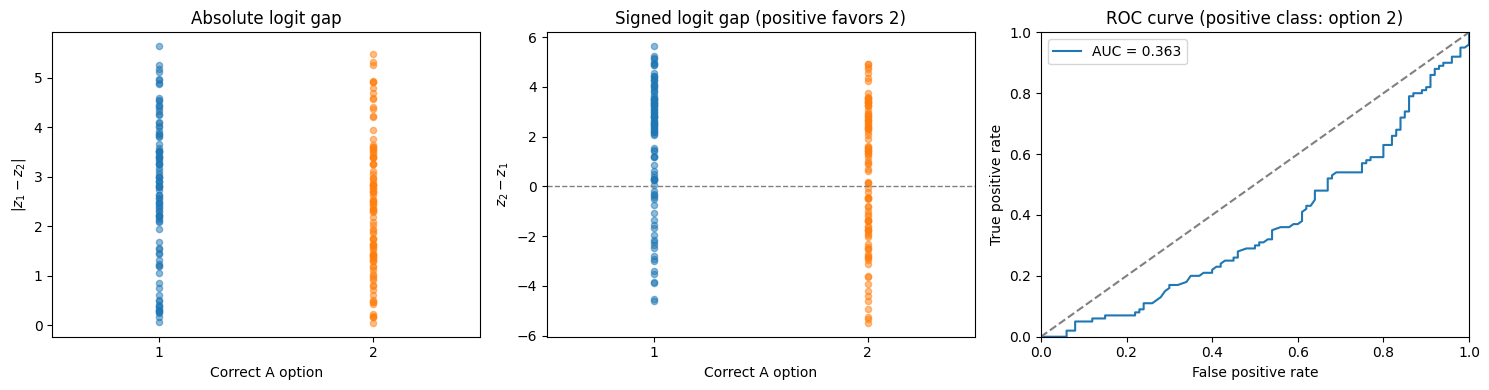

In [20]:
#@title Cell 16: Test logit-gap plots and ROC AUC
# Run Cell 15 first. Reuses all test results without another model pass.
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

labels = logit_gaps["correct_option"].to_numpy()
delta = logit_gaps["signed_gap"].to_numpy()  # z2 - z1
auc = roc_auc_score(labels == 2, delta)
print(f"ROC AUC: {auc:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title, ylabel in zip(
    axes[:2], ["absolute_gap", "signed_gap"],
    ["Absolute logit gap", "Signed logit gap (positive favors 2)"],
    [r"$|z_1 - z_2|$", r"$z_2 - z_1$"],
):
    for option in (1, 2):
        values = logit_gaps.loc[labels == option, column]
        ax.scatter([option] * len(values), values, alpha=0.5, s=20)
    ax.set(title=title, xlabel="Correct A option", ylabel=ylabel, xlim=(0.5, 2.5))
    ax.set_xticks([1, 2])
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)

fpr, tpr, _ = roc_curve(labels == 2, delta)
axes[2].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[2].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[2].set(title="ROC curve (positive class: option 2)",
            xlabel="False positive rate", ylabel="True positive rate",
            xlim=(0, 1), ylim=(0, 1))
axes[2].legend()
plt.tight_layout()
plt.show()


With training now working, these diagnostics still complement accuracy: logit gaps show score direction and separation, while ROC AUC summarizes how signed scores rank the two correct-option groups. They remain here as a record of the investigation, without attributing the earlier pattern to a particular cause.


In [21]:
model.eval()
s = train_data[0]

prompt = PROMPT_TEMPLATE.format(
    question_A=s["question_A"],
    question_B=s["question_B"],
    choice_1=s["choices"][0],
    choice_2=s["choices"][1],
)

inputs = tokenizer(prompt, return_tensors="pt").to(device)

with torch.inference_mode():
    output = model(
        **inputs,
        output_hidden_states=True,
        logits_to_keep=1,
        use_cache=False
    )

    # Final hidden state, before the output projection
    h = output.hidden_states[-1][0, -1].float()

    # Recompute the two output projection scores in FP32
    head_weights = model.get_output_embeddings().weight[
        choice_ids
    ].float()

    raw_logits = head_weights @ h

    cap = model.config.final_logit_softcapping
    capped_fp32 = raw_logits if cap is None else cap * torch.tanh(raw_logits / cap)

    print("Raw pre-cap logits:", raw_logits.tolist())
    print("Recomputed FP32 logits (current softcap setting):", capped_fp32.tolist())
    print(f"Actual model logits ({output.logits.dtype}):",
          output.logits[0, -1, choice_ids].tolist())

Raw pre-cap logits: [51.33184814453125, 39.413978576660156]
Recomputed FP32 logits (current softcap setting): [28.103328704833984, 25.957008361816406]
Actual model logits (torch.float16): [28.109375, 25.953125]


## Experiment 1: shortcut use versus memorization

Previously reported results motivating this check:

| Model | Dataset | Input | Correct | Accuracy |
|---|---|---|---|---|
| Pretrained | Training | A only | 136/200 | 68.0% |
| Pretrained | Training | A+B | 100/200 | 50.0% |
| Post-training | Test | A only | 190/200 | 95.0% |
| Post-training | Test | A+B | 116/200 | 58.0% |
| Post-training | Training | A+B | 200/200 | 100.0% |

We want to compare two explanations:

- **H1 — shortcut use:** The model learned a shortcut from the aligned A/B format that transfers to new aligned question pairs.
- **H0 — memorization/overfitting:** The high training accuracy mainly reflects fitting the original training examples, with limited transfer to new pairs.

**Prediction:** Accuracy around **90%** on the new cases would support H1; accuracy around **50%** would support H0. These are approximate reference points, not automatic classification cutoffs.

The next cells evaluate the current trained model on **30 new cases** with both correct answers in the same option, as in training. The questions cover new facts relative to the existing train/test questions, with A/B matched by topic and approximate difficulty and lengths kept within the existing ranges. Correct options are balanced 15/15; case order and option positions were shuffled with seed 42. These cases remain separate from both original datasets and are evaluated without further training.


In [22]:
#@title Cell 17: New aligned cases — 30 A/B pairs and separate grading keys
# Questions/options were shuffled offline with seed 42; A and B agree in every case.
new_aligned_text = r"""
NA15	Which set operation keeps only elements common to both sets?	Which set operation collects all elements in either set?	union / intersection ||| intersection / union	A=2;B=2
NA24	What term describes repeated initial consonant sounds in nearby words?	What term means a word that imitates a sound?	rhyme / alliteration ||| alliteration / onomatopoeia	A=2;B=2
NA16	Which line divides Earth into northern and southern hemispheres?	Which line defines zero degrees of longitude?	prime meridian / Tropic of Cancer ||| equator / prime meridian	A=2;B=2
NA12	What underground rock layer stores and transmits groundwater?	What marks the upper surface of saturated groundwater?	magma chamber / tree line ||| aquifer / water table	A=2;B=2
NA17	What landform has water on three sides?	What narrow strip of land connects two larger landmasses?	peninsula / isthmus ||| island / archipelago	A=1;B=1
NA21	Which ancient people developed cuneiform writing?	Which ancient civilization built the Parthenon in Athens?	Romans / Vikings ||| Sumerians / Greeks	A=2;B=2
NA18	What map lines join points at equal elevation?	What map lines join places with equal air pressure?	contour lines / isobars ||| isobars / contour lines	A=1;B=1
NA08	What neurons carry signals from receptors into the central nervous system?	What neurons carry signals from the central nervous system to muscles?	sensory neurons / motor neurons ||| motor neurons / sensory neurons	A=1;B=1
NA27	What does HTML primarily describe on a web page?	What does CSS primarily control on a web page?	styling / database queries ||| structure / styling	A=2;B=2
NA20	Who was the first person to walk on the Moon?	Who was the first person to travel into space?	Neil Armstrong / Yuri Gagarin ||| Yuri Gagarin / Neil Armstrong	A=1;B=1
NA10	What cell division produces two genetically identical daughter cells?	What cell division halves chromosome numbers in animal gamete formation?	meiosis / mitosis ||| mitosis / meiosis	A=2;B=2
NA13	Which rock fold has its oldest layers at the center?	Which rock fold has its youngest layers at the center?	syncline / anticline ||| anticline / syncline	A=2;B=2
NA28	What process turns readable data into coded ciphertext?	What process reduces a computer file's storage size?	encryption / compression ||| compression / encryption	A=1;B=1
NA02	What wave effect spreads waves through a narrow opening?	What effect makes overlapping waves reinforce or cancel each other?	diffraction / interference ||| refraction / reflection	A=1;B=1
NA30	What sewing stitch makes a temporary removable seam?	What edge treatment folds and secures the edge of fabric?	backstitch / pleating ||| basting / hemming	A=2;B=2
NA03	How do two north magnetic poles interact?	How do north and south magnetic poles interact?	repel / attract ||| attract / repel	A=1;B=1
NA04	What substance speeds a reaction without being used up?	What substance reduces the rate of a chemical reaction?	reactant / catalyst ||| catalyst / inhibitor	A=2;B=2
NA22	Which material is shaped and fired to make pottery?	What coating gives pottery a glassy surface after firing?	steel / varnish ||| clay / glaze	A=2;B=2
NA07	Which cell structures assemble proteins from amino acids?	Which cell organelles digest worn-out components?	ribosomes / lysosomes ||| mitochondria / chloroplasts	A=1;B=1
NA05	What property is a substance's mass per unit volume?	What property measures a fluid's resistance to flow?	viscosity / density ||| density / viscosity	A=2;B=2
NA29	What tool checks whether a surface is horizontal?	What tool uses a hanging weight to check vertical alignment?	spirit level / plumb bob ||| plumb bob / spirit level	A=1;B=1
NA11	What plant growth response is directed by light?	What plant growth response is directed by gravity?	phototropism / gravitropism ||| gravitropism / phototropism	A=1;B=1
NA14	Which star lies close to Earth's north celestial pole?	Which star is brightest in Earth's night sky?	Sirius / Polaris ||| Polaris / Sirius	A=2;B=2
NA23	Which figure of speech compares using the word 'like'?	Which figure of speech gives objects human traits?	simile / personification ||| metaphor / hyperbole	A=1;B=1
NA06	What does an atom's mass number count?	What does an atom's atomic number count?	protons and neutrons / protons ||| protons and electrons / neutrons	A=1;B=1
NA25	What script instructions describe how actors should move?	What script text contains characters' spoken conversations?	stage directions / dialogue ||| dialogue / stage directions	A=1;B=1
NA01	What simple machine is a rigid bar pivoting on a fulcrum?	What simple machine uses a grooved wheel and rope?	pulley / screw ||| lever / pulley	A=2;B=2
NA26	What program translates source code into machine code?	What program helps locate errors in other programs?	compiler / debugger ||| debugger / compiler	A=1;B=1
NA09	What immune proteins bind to specific foreign antigens?	What immune cells engulf and digest invading microbes?	antibodies / phagocytes ||| hemoglobin / red blood cells	A=1;B=1
NA19	Which empire had its capital at Tenochtitlan?	Which empire had its capital at Cuzco?	Inca Empire / Aztec Empire ||| Aztec Empire / Inca Empire	A=2;B=2
""".strip()

new_aligned_data = []
new_aligned_rubric = {}
for line in new_aligned_text.splitlines():
    case_id, qA, qB, choices, key = line.split("	")
    a, b = [int(part.split("=")[1]) for part in key.split(";")]
    assert a == b and a in (1, 2)
    new_aligned_data.append({
        "id": case_id, "question_A": qA, "question_B": qB,
        "choices": choices.split(" ||| "),
    })
    new_aligned_rubric[case_id] = {"correct_A": a, "correct_B": b}
assert len(new_aligned_data) == len(new_aligned_rubric) == 30
assert sum(key["correct_A"] == 1 for key in new_aligned_rubric.values()) == 15


In [23]:
#@title Cell 18: Post-training accuracy on the 30 new aligned cases
# Run Cell 17 with the existing trained model loaded; no further training.
assert hasattr(model, "peft_config"), "Load your trained LoRA adapter or finish Cell 11 first."
model.eval()
new_aligned_rows = []
with torch.inference_mode():
    for sample in new_aligned_data:
        prompt = PROMPT_TEMPLATE.format(
            question_A=sample["question_A"], question_B=sample["question_B"],
            choice_1=sample["choices"][0], choice_2=sample["choices"][1],
        )
        inputs = tokenizer(prompt, return_tensors="pt").to(device)
        logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[0, -1].float()
        p1, p2 = logits.softmax(dim=-1)[choice_ids].tolist()
        correct_option = new_aligned_rubric[sample["id"]]["correct_A"]
        tie = p1 == p2
        preferred = 3 - correct_option if tie else 1 if p1 > p2 else 2
        new_aligned_rows.append({
            "id": sample["id"], "question_A": sample["question_A"],
            "prob_1": p1, "prob_2": p2, "preferred_option": preferred, "tie": tie,
            "correct_option": correct_option, "correct": preferred == correct_option,
        })

new_aligned_results = pd.DataFrame(new_aligned_rows)
display(new_aligned_results.head(20).style.format({"prob_1": "{:.4g}", "prob_2": "{:.4g}"}))
correct = new_aligned_results["correct"]
print(f"Post-training new aligned cases, A + B: {correct.sum()}/{len(correct)} correct ({correct.mean():.1%})")


,id,question_A,prob_1,prob_2,preferred_option,tie,correct_option,correct
0,NA15,Which set operation keeps only elements common to both sets?,0.3668,0.5506,2,False,2,True
1,NA24,What term describes repeated initial consonant sounds in nearby words?,0.0716,0.8454,2,False,2,True
2,NA16,Which line divides Earth into northern and southern hemispheres?,0.04397,0.8831,2,False,2,True
3,NA12,What underground rock layer stores and transmits groundwater?,0.004604,0.9195,2,False,2,True
4,NA17,What landform has water on three sides?,0.9,0.01897,1,False,1,True
5,NA21,Which ancient people developed cuneiform writing?,0.006079,0.9455,2,False,2,True
6,NA18,What map lines join points at equal elevation?,0.7326,0.1687,1,False,1,True
7,NA08,What neurons carry signals from receptors into the central nervous system?,0.3658,0.5322,2,False,1,False
8,NA27,What does HTML primarily describe on a web page?,0.006138,0.9399,2,False,2,True
9,NA20,Who was the first person to walk on the Moon?,0.6971,0.2061,1,False,1,True


Post-training new aligned cases, A + B: 25/30 correct (83.3%)


### Experiment 1 outcome and next-step rationale

| Checkpoint | Record |
|---|---|
| H1 prediction: transferable shortcut use | Accuracy around 90% on the new aligned cases |
| H0 prediction: memorization/overfitting | Accuracy around 50% on the new aligned cases |
| Observed Experiment 1 result | 24/30 correct (80.0%) |
| Comparison with the predictions | Transfer to new aligned cases is evident; this does not uniquely identify shortcut use |
| Selected next experiment | Experiment 2: swap only B's answer positions within matched pairs |
| Justification for that order | Test whether B's answer placement affects A's predictions and margins while holding the questions and answer texts fixed |

Cell 23 records the statistical confidence and combined conclusions.


## Experiment 2: model using Question 2 vs not using Question 2

Here Question 1 is **A** and Question 2 is **B**. Experiment 2 now uses **100 matched pairs (200 prompts)**: the original 30 pilot pairs plus 70 additional pairs. All are separate from the original training/test datasets and Experiment 1. Both versions use the existing A+B prompt and the current trained model, without further training.

Within each pair, both questions and all answer texts remain identical. A's answer positions and correct option stay fixed. Only B's answer positions are swapped: the aligned version has A/B answers correct in the same option; the conflicting version has them correct in opposite options. A's correct position is balanced across pairs: 50 option-1 and 50 option-2. The original 30 cases and their option positions are preserved; additional option positions and the expanded case order were shuffled with seed 42.

Each result row compares the two assigned predictions and signed logit margins, `z_correct_A − z_other`. Positive margins favor the correct A option. `margin_change` is conflicting minus aligned, so a negative change means less preference for the correct A option in the conflicting version. `prediction_changed` compares the assigned option numbers. Exact probability ties remain flagged and assigned the incorrect option; changes involving ties therefore follow this grading convention. All 100 paired rows are retained, with the first 20 displayed.


In [24]:
#@title Cell 19: Experiment 2 — 100 matched pairs and separate grading keys
# Original 30 cases/option positions retained; 70 added; expanded order shuffled with seed 42.
experiment2_text = r"""
EP207	What galaxy type has a central bulge and curved arms?	What galaxy type has a smooth oval shape?	spiral galaxy / elliptical galaxy ||| elliptical galaxy / spiral galaxy	A=1;B=1
EP280	What European cultural movement revived interest in classical learning?	What historical transformation replaced much hand production with machinery?	Industrial Revolution / Renaissance ||| Renaissance / Industrial Revolution	A=2;B=2
EP279	Which Chinese dynasty built the Terracotta Army?	Which Chinese dynasty employed the explorer Zheng He?	Ming / Qin ||| Qin / Ming	A=2;B=2
EP253	Which Earth layer is liquid and mainly iron?	Which Earth layer is solid and mainly iron?	outer core / inner core ||| inner core / outer core	A=1;B=1
EP291	What kitchen action removes the outer skin from produce?	What kitchen action cuts food into small cubes?	dicing / peeling ||| peeling / dicing	A=2;B=2
EP245	What substances are consumed in a chemical reaction?	What substances are formed in a chemical reaction?	products / reactants ||| reactants / products	A=2;B=2
EP218	Which tropical grassland biome contains scattered trees?	Which Arctic biome is mostly treeless and often has permafrost?	savanna / tundra ||| tundra / savanna	A=1;B=1
EP224	What word part is added before a word's root?	What word part is added after a word's root?	suffix / prefix ||| prefix / suffix	A=2;B=2
EP240	What are the threadlike filaments of filamentous fungi called?	What is a network of fungal filaments called?	stomata / xylem ||| hyphae / mycelium	A=2;B=2
EP275	What sentence type gives a command or instruction?	What sentence type makes a statement?	interrogative / imperative ||| imperative / declarative	A=2;B=2
EP239	What tube carries urine from a kidney to the bladder?	What tube carries urine from the bladder out of the body?	ureter / urethra ||| urethra / ureter	A=1;B=1
EP213	What solid has matching parallel bases joined by parallelograms?	What solid has triangular faces meeting at one apex?	pyramid / prism ||| prism / pyramid	A=2;B=2
EP243	In proton-transfer chemistry, what substance donates a proton?	In proton-transfer chemistry, what substance accepts a proton?	acid / base ||| base / acid	A=1;B=1
EP251	What particles carry the electromagnetic force?	What particles carry the strong force between quarks?	photons / gluons ||| gluons / photons	A=1;B=1
EP216	What steep coastal inlet was carved by a glacier?	What ring-shaped coral island surrounds a lagoon?	atoll / fjord ||| fjord / atoll	A=2;B=2
EP202	What deformation disappears when the force is removed?	What deformation remains after the force is removed?	elastic deformation / plastic deformation ||| plastic deformation / elastic deformation	A=1;B=1
EP250	What quantity is the rate of change of position?	What quantity is the rate of change of velocity?	acceleration / velocity ||| velocity / acceleration	A=2;B=2
EP214	What instrument indicates magnetic north?	What instrument measures temperature?	barometer / anemometer ||| compass / thermometer	A=2;B=2
EP234	What counting term describes a selection where order matters?	What counting term describes a selection where order does not matter?	combination / permutation ||| permutation / combination	A=2;B=2
EP244	What solution holds its maximum dissolved solute at a given temperature?	What solution can dissolve additional solute at a given temperature?	saturated solution / unsaturated solution ||| unsaturated solution / saturated solution	A=1;B=1
EP206	What heart chambers receive blood returning through veins?	What heart chambers pump blood into arteries?	atria / ventricles ||| ventricles / atria	A=1;B=1
EP237	In DNA, which base pairs with adenine?	In DNA, which base pairs with guanine?	cytosine / thymine ||| thymine / cytosine	A=2;B=2
EP287	What hand tool turns hexagonal nuts and bolts?	What hand tool shaves thin layers from wood?	wrench / plane ||| plane / wrench	A=1;B=1
EP215	Which electrode is the site of oxidation?	Which electrode is the site of reduction?	cathode / anode ||| anode / cathode	A=2;B=2
EP222	Which musical element is the tune of a piece?	Which musical element concerns combinations of simultaneous notes?	rhythm / tempo ||| melody / harmony	A=2;B=2
EP265	Which Hindu festival is known as the festival of lights?	Which Hindu festival is known for throwing colored powder?	Diwali / Holi ||| Holi / Diwali	A=1;B=1
EP285	What database key uniquely identifies each row in a table?	What database key references a key in another table?	primary key / foreign key ||| foreign key / primary key	A=1;B=1
EP258	What term means moving permanently into a foreign country?	What term means leaving one's country to settle abroad?	emigration / immigration ||| immigration / emigration	A=2;B=2
EP205	What inner-ear structure contains the hearing receptors?	What vibrating membrane separates the outer and middle ear?	retina / cornea ||| cochlea / eardrum	A=2;B=2
EP231	What line touches a circle at exactly one point?	What line intersects a circle at two distinct points?	tangent / secant ||| secant / tangent	A=1;B=1
EP2100	What gymnastics apparatus is a narrow raised beam?	What gymnastics apparatus has two bars at different heights?	balance beam / uneven bars ||| uneven bars / balance beam	A=1;B=1
EP271	Which poem form traditionally has fourteen lines?	In English, which Japanese poetic form usually has three lines?	limerick / sonnet ||| sonnet / haiku	A=2;B=2
EP292	What are the lengthwise threads in woven cloth called?	What are the crosswise threads in woven cloth called?	weft / warp ||| warp / weft	A=2;B=2
EP210	What sunburn-causing radiation does the ozone layer absorb?	What radiation do greenhouse gases absorb from Earth's surface?	infrared / ultraviolet ||| ultraviolet / infrared	A=2;B=2
EP256	What map feature explains the symbols used?	What map diagram shows the cardinal directions?	compass rose / legend ||| legend / compass rose	A=2;B=2
EP273	What term means the main character in a story?	What term means a character opposing a story's main character?	protagonist / antagonist ||| antagonist / protagonist	A=1;B=1
EP212	What single example disproves a universal mathematical claim?	What unproved mathematical statement is proposed as true?	axiom / theorem ||| counterexample / conjecture	A=2;B=2
EP221	What is a public vote on a specific issue called?	What written request gathers signatures to seek official action?	petition / referendum ||| referendum / petition	A=2;B=2
EP262	What paper records a voter's choice in an election?	What is an electoral district represented by a legislator called?	manifesto / cabinet ||| ballot / constituency	A=2;B=2
EP233	What matrix has equal numbers of rows and columns?	What square matrix has ones on its diagonal and zeros elsewhere?	square matrix / identity matrix ||| nonsquare matrix / zero matrix	A=1;B=1
EP254	What geological fracture has displaced rock along it?	What geological fracture has no appreciable rock displacement?	fault / joint ||| joint / fault	A=1;B=1
EP230	What abrasive sheet smooths wood before painting?	What bench-mounted tool clamps a workpiece between two jaws?	wax paper / ruler ||| sandpaper / vise	A=2;B=2
EP223	What is a life story written by another person called?	What is an author's account of their own life called?	biography / autobiography ||| autobiography / biography	A=1;B=1
EP261	Which branch of government makes laws?	Which branch of government interprets laws in court?	legislative / judicial ||| judicial / legislative	A=1;B=1
EP295	Which pedal disengages a manual car's engine from its gearbox?	What lever selects gears in a manual car?	clutch pedal / gear lever ||| accelerator pedal / parking brake lever	A=1;B=1
EP264	Which religion's sacred text is the Quran?	Which religion's sacred texts include the Vedas?	Christianity / Buddhism ||| Islam / Hinduism	A=2;B=2
EP238	Which retinal cells support vision in dim light?	Which retinal cells primarily detect color?	rods / cones ||| cones / rods	A=1;B=1
EP284	What is a horizontal group of spreadsheet cells called?	What is a vertical group of spreadsheet cells called?	column / row ||| row / column	A=2;B=2
EP255	What process brings deep ocean water to the surface?	What process sends surface ocean water toward the depths?	downwelling / upwelling ||| upwelling / downwelling	A=2;B=2
EP268	Which dance style uses metal plates on shoes?	Which dance style includes the position en pointe?	tap / ballet ||| ballet / tap	A=1;B=1
EP298	Which swimming stroke uses alternating arm pulls while lying face up?	Which swimming stroke uses simultaneous arm sweeps and dolphin kicks?	butterfly / backstroke ||| backstroke / butterfly	A=2;B=2
EP293	What is the fabric margin between a seam and cut edge?	What guideline shows the direction of lengthwise fabric threads?	grainline / seam allowance ||| seam allowance / grainline	A=2;B=2
EP203	What is passive spreading from high to low concentration called?	What is water diffusion across a selectively permeable membrane called?	diffusion / osmosis ||| active transport / active transport	A=1;B=1
EP267	Which plucked string instrument is prominent in Indian classical music?	Which long wind instrument originated among Aboriginal Australians?	sitar / didgeridoo ||| didgeridoo / sitar	A=1;B=1
EP204	What term means having two identical alleles for a gene?	What term means having two different alleles for a gene?	heterozygous / homozygous ||| homozygous / heterozygous	A=2;B=2
EP290	What method cooks food gently in liquid just below boiling?	What method briefly boils food before quickly chilling it?	simmering / blanching ||| blanching / simmering	A=1;B=1
EP276	Which punctuation mark links two closely related independent clauses?	Which punctuation mark shows omitted words in a quotation?	apostrophe / colon ||| semicolon / ellipsis	A=2;B=2
EP263	What is a Jewish place of worship called?	What is a Muslim place of worship called?	synagogue / mosque ||| mosque / synagogue	A=1;B=1
EP297	What airport strip is used for takeoffs and landings?	What airport path links runways with aircraft parking areas?	runway / taxiway ||| taxiway / runway	A=1;B=1
EP257	What geographical term means a group of islands?	What term describes a country with no sea coast?	continent / coastal ||| archipelago / landlocked	A=2;B=2
EP225	What is the central struggle in a story called?	What term means a story's time and place?	conflict / setting ||| setting / conflict	A=1;B=1
EP281	What programming construct repeats a block of instructions?	What programming construct selects a branch based on a condition?	loop / conditional ||| conditional / loop	A=1;B=1
EP274	What sentence part identifies who or what is being discussed?	What sentence part states something about its subject?	predicate / subject ||| subject / predicate	A=2;B=2
EP266	What Japanese art creates shapes by folding paper?	What Japanese art involves arranging flowers?	ikebana / origami ||| origami / ikebana	A=2;B=2
EP270	What film form presents factual subjects rather than fictional stories?	What film technique makes still drawings appear to move?	fantasy / live action ||| documentary / animation	A=2;B=2
EP226	What data structure follows last in, first out?	What data structure follows first in, first out?	stack / queue ||| queue / stack	A=1;B=1
EP227	What operation joins text strings end to end?	What operation arranges data items in a chosen order?	sorting / concatenation ||| concatenation / sorting	A=2;B=2
EP277	Which Venetian traveler described journeys to China?	Which Moroccan traveler narrated the account called the Rihla?	Marco Polo / Ibn Battuta ||| Ibn Battuta / Marco Polo	A=1;B=1
EP252	Which seismic body waves pass through solids and liquids?	Which seismic body waves travel only through solids?	P waves / S waves ||| S waves / P waves	A=1;B=1
EP241	Which glands release adrenaline during a fight-or-flight response?	Which gland releases melatonin to regulate sleep timing?	pineal gland / adrenal glands ||| adrenal glands / pineal gland	A=2;B=2
EP217	What smaller stream flows into a larger river?	What river branch flows away from the main channel?	tributary / distributary ||| distributary / tributary	A=1;B=1
EP219	Which Greek city-state was famed for its military training?	Which Roman city was buried by Vesuvius in AD 79?	Athens / Carthage ||| Sparta / Pompeii	A=2;B=2
EP208	What fossils preserve footprints or burrows?	What fossil type preserves an organism's bones or shells?	trace fossils / body fossils ||| body fossils / trace fossils	A=1;B=1
EP242	Which main taxonomic rank lies directly above species?	Which main taxonomic rank lies directly above genus?	family / species ||| genus / family	A=2;B=2
EP209	What process lets surface water enter soil?	What process moves water downward through soil pores?	infiltration / percolation ||| evaporation / condensation	A=1;B=1
EP272	What literary form uses humor to criticize society?	What story form uses characters to represent abstract ideas?	elegy / memoir ||| satire / allegory	A=2;B=2
EP289	Which method cooks food quickly in a little hot fat?	Which method cooks food fully submerged in hot oil?	sautéing / deep-frying ||| deep-frying / sautéing	A=1;B=1
EP299	What tennis shot is hit before the ball bounces?	What tennis shot sends the ball high over an opponent?	volley / lob ||| groundstroke / drop shot	A=1;B=1
EP260	What are goods sold to another country called?	What are goods bought from another country called?	exports / imports ||| imports / exports	A=1;B=1
EP294	What clothing fastener passes through a slit in fabric?	What two-part clothing fastener clicks together when pressed?	button / snap ||| snap / button	A=1;B=1
EP232	What are two angles whose measures total 90 degrees called?	What are two angles whose measures total 180 degrees called?	supplementary angles / complementary angles ||| complementary angles / supplementary angles	A=2;B=2
EP269	What stage speech reveals a character's thoughts while alone?	What brief stage remark is supposedly unheard by other characters?	aside / soliloquy ||| soliloquy / aside	A=2;B=2
EP211	What polynomial has exactly one nonzero term?	What polynomial has exactly two nonzero terms?	monomial / binomial ||| binomial / monomial	A=1;B=1
EP296	What bicycle part transfers power between sprockets?	What bicycle part shifts the chain between sprockets?	chain / derailleur ||| derailleur / chain	A=1;B=1
EP278	What animal-skin material was used for medieval book pages?	What plant-based writing material did ancient Egyptians use?	papyrus / parchment ||| parchment / papyrus	A=2;B=2
EP220	What title was used by rulers of ancient Egypt?	What title was held by Japan's hereditary military rulers?	pharaoh / shogun ||| shogun / pharaoh	A=1;B=1
EP283	In Git, what records a snapshot of tracked project files?	In Git, what names a separate line of development?	branch / commit ||| commit / branch	A=2;B=2
EP288	What hand tool cuts metal with a toothed blade?	What hand tool smooths metal with a roughened surface?	file / hacksaw ||| hacksaw / file	A=2;B=2
EP235	What circle passes through all three vertices of a triangle?	What circle touches all three sides inside a triangle?	circumcircle / incircle ||| incircle / circumcircle	A=1;B=1
EP286	Which editing command reverses the most recent action?	Which editing command reapplies an action you just undid?	undo / redo ||| redo / undo	A=1;B=1
EP201	Which device changes alternating voltage using electromagnetic induction?	Which device converts alternating current into direct current?	rectifier / transformer ||| transformer / rectifier	A=2;B=2
EP246	What atomic orbital type has a spherical shape?	What atomic orbital type has a two-lobed shape?	s orbital / p orbital ||| p orbital / s orbital	A=1;B=1
EP248	What effect shifts sound frequency through relative source-observer motion?	What occurs when driving frequency matches a system's natural frequency?	Doppler effect / resonance ||| resonance / Doppler effect	A=1;B=1
EP229	What cooking method uses dry heat inside an oven?	What cooking method uses vapor from boiling water?	baking / steaming ||| steaming / baking	A=1;B=1
EP247	What functional group defines an alcohol?	What functional group defines a carboxylic acid?	hydroxyl group / carboxyl group ||| carboxyl group / hydroxyl group	A=1;B=1
EP282	What search checks list items one by one?	What search repeatedly halves a sorted search interval?	binary search / linear search ||| linear search / binary search	A=2;B=2
EP259	What system exchanges goods directly without using money?	What term means a system of money used in a country?	credit / barter ||| barter / currency	A=2;B=2
EP236	Which vector product returns a scalar?	Which three-dimensional vector product returns a perpendicular vector?	dot product / cross product ||| cross product / dot product	A=1;B=1
EP249	What thermodynamic process occurs with no heat transfer?	What thermodynamic process occurs at constant temperature?	isothermal process / adiabatic process ||| adiabatic process / isothermal process	A=2;B=2
EP228	Which SQL command removes a table and its definition?	Which SQL command retrieves rows from a database?	DROP / SELECT ||| DELETE / UPDATE	A=1;B=1
""".strip()

experiment2_pairs = []
experiment2_rubric = {}
for line in experiment2_text.splitlines():
    pair_id, qA, qB, choices, key = line.split("	")
    choices = choices.split(" ||| ")
    a, b = [int(part.split("=")[1]) for part in key.split(";")]
    assert a == b and a in (1, 2)
    a1, b1 = choices[0].split(" / ", 1)
    a2, b2 = choices[1].split(" / ", 1)
    experiment2_pairs.append({
        "id": pair_id, "question_A": qA, "question_B": qB,
        "aligned": choices,
        "conflicting": [a1 + " / " + b2, a2 + " / " + b1],
    })
    experiment2_rubric[pair_id] = {"correct_A": a, "aligned_B": b, "conflicting_B": 3 - b}
assert len(experiment2_pairs) == len(experiment2_rubric) == 100
assert sum(key["correct_A"] == 1 for key in experiment2_rubric.values()) == 50


In [25]:
#@title Cell 20: Experiment 2 — paired predictions and signed logit margins
# Run Cell 19 with the existing trained model loaded; no further training.
assert hasattr(model, "peft_config"), "Load your trained LoRA adapter or finish Cell 11 first."
assert len(experiment2_pairs) == len(experiment2_rubric) == 100, "Run the updated Cell 19 on all 100 pairs first."
model.eval()
experiment2_rows = []
with torch.inference_mode():
    for pair in experiment2_pairs:
        correct_option = experiment2_rubric[pair["id"]]["correct_A"]
        row = {"id": pair["id"], "correct_option": correct_option}
        for condition in ("aligned", "conflicting"):
            prompt = PROMPT_TEMPLATE.format(
                question_A=pair["question_A"], question_B=pair["question_B"],
                choice_1=pair[condition][0], choice_2=pair[condition][1],
            )
            inputs = tokenizer(prompt, return_tensors="pt").to(device)
            logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[0, -1].float()
            assert torch.isfinite(logits).all().item(), f"Non-finite logits for {pair['id']} ({condition})"
            p1, p2 = logits.softmax(dim=-1)[choice_ids].tolist()
            z1, z2 = logits[choice_ids].tolist()
            tie = p1 == p2
            preferred = 3 - correct_option if tie else 1 if p1 > p2 else 2
            row[f"{condition}_option"] = preferred
            row[f"{condition}_margin"] = z1 - z2 if correct_option == 1 else z2 - z1
            row[f"{condition}_tie"] = tie
        row["margin_change"] = row["conflicting_margin"] - row["aligned_margin"]
        row["prediction_changed"] = row["aligned_option"] != row["conflicting_option"]
        experiment2_rows.append(row)

experiment2_results = pd.DataFrame(experiment2_rows)
display(experiment2_results.head(20).style.format({
    "aligned_margin": "{:.6g}", "conflicting_margin": "{:.6g}", "margin_change": "{:.6g}",
}))
for condition in ("aligned", "conflicting"):
    correct = experiment2_results[f"{condition}_option"] == experiment2_results["correct_option"]
    print(f"Experiment 2 {condition}: {correct.sum()}/{len(correct)} correct ({correct.mean():.1%})")
print(f"Assigned-option changes: {experiment2_results['prediction_changed'].sum()}/{len(experiment2_results)} pairs")


,id,correct_option,aligned_option,aligned_margin,aligned_tie,conflicting_option,conflicting_margin,conflicting_tie,margin_change,prediction_changed
0,EP207,1,2,-3.07812,False,1,3.78125,False,6.85938,True
1,EP280,2,2,0.03125,False,1,-1.70312,False,-1.73438,True
2,EP279,2,2,0.828125,False,1,-0.390625,False,-1.21875,True
3,EP253,1,1,0.734375,False,2,-2.4375,False,-3.17188,True
4,EP291,2,2,1.90625,False,2,0.546875,False,-1.35938,False
5,EP245,2,2,1.89062,False,2,2.125,False,0.234375,False
6,EP218,1,1,0.765625,False,2,-2.15625,False,-2.92188,True
7,EP224,2,2,1.9375,False,2,2.14062,False,0.203125,False
8,EP240,2,2,5.15625,False,2,0.921875,False,-4.23438,False
9,EP275,2,1,-0.5,False,2,0.515625,False,1.01562,True


Experiment 2 aligned: 76/100 correct (76.0%)
Experiment 2 conflicting: 44/100 correct (44.0%)
Assigned-option changes: 54/100 pairs


### Experiment 2: correct-A margins and paired differences

The initial **30-pair pilot** reported **24/30 aligned prompts correct (80.0%)**, **17/30 conflicting prompts correct (56.7%)**, and **13/30 assigned-option changes**. We retained those 30 pairs and added 70, expanding this evaluation to 100 pairs. The saved summaries below use the expanded 100-pair set. To quantify the paired score changes before planning Experiment 3, we summarize the correct-A option-logit margin for each prompt:

`M_A = z_correct_A − z_incorrect_A`

For each pair, define `D = M_A(aligned) − M_A(conflicting)`. We report the mean and **sample SD (`ddof=1`)** of aligned `M_A`, conflicting `M_A`, and `D` across all 100 pairs, including ties. A substantially positive **mean D** would support the hypothesis that Question 2's answer placement affects Gemma's decisions; no numeric cutoff is specified here.

Cell 20 already records these per-prompt margins. Cell 21 reuses them; all
per-pair values are retained in `experiment2_margins` without rerunning the model.

For `D`, we also report the median and the proportion strictly above zero.
This proportion counts how often alignment gives a larger correct-A margin,
with all 100 pairs retained in the denominator.


In [26]:
#@title Cell 21: Experiment 2 — correct-A margins and paired D statistics
# Reuse all 100 pairs from Cell 20; no model passes or filtering of ties.
assert len(experiment2_results) == experiment2_results["id"].nunique() == 100, "Run Cell 20 on all 100 pairs first."
experiment2_margins = experiment2_results.set_index("id")[["aligned_margin", "conflicting_margin"]].rename(columns={
    "aligned_margin": "M_A (aligned)", "conflicting_margin": "M_A (conflicting)",
})
# D is aligned minus conflicting, opposite to Cell 20's margin_change.
experiment2_margins["D"] = experiment2_margins["M_A (aligned)"] - experiment2_margins["M_A (conflicting)"]
assert experiment2_margins.notna().all().all(), "Missing margins; rerun Cell 20."
experiment2_margin_summary = pd.DataFrame({
    "n": experiment2_margins.count(),
    "mean": experiment2_margins.mean(),
    "sample_SD": experiment2_margins.std(ddof=1),
})
display(experiment2_margin_summary.style.format({"mean": "{:.6g}", "sample_SD": "{:.6g}"}))

D = experiment2_margins["D"]
print(f"Median D: {D.median():.6g}")
print(f"Proportion D > 0: {(D > 0).mean():.1%} ({(D > 0).sum()}/{len(D)} pairs)")


,n,mean,sample_SD
M_A (aligned),100,1.44031,2.08539
M_A (conflicting),100,-0.573125,2.72676
D,100,2.01344,3.60998


Median D: 2.07031
Proportion D > 0: 68.0% (68/100 pairs)


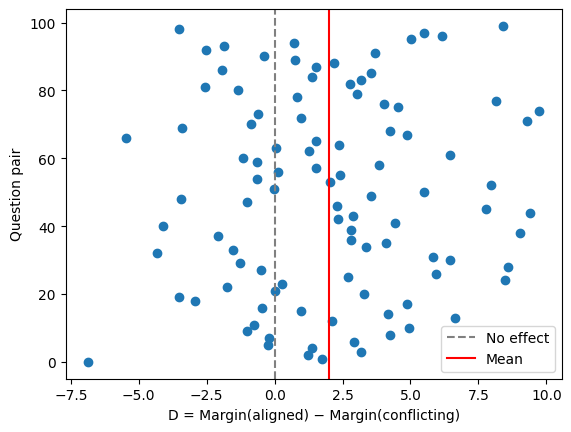

In [27]:
#@title Cell 22: Experiment 2 — distribution of paired margin differences
# Run Cell 21 first; use all stored D values without rerunning the model.
import matplotlib.pyplot as plt

D = experiment2_margins["D"]
assert len(D) == 100, "Run Cell 21 on the expanded 100-pair results first."
plt.figure()
plt.scatter(D, range(len(D)))
plt.axvline(0, linestyle="--", color="gray", label="No effect")
plt.axvline(D.mean(), color="red", label="Mean")
plt.xlabel("D = Margin(aligned) − Margin(conflicting)")
plt.ylabel("Question pair")
plt.legend()
plt.show()


## Cell 23: Conclusions from Experiments 1 and 2

These conclusions use the saved results in Cells 18, 20, and 21; no model rerun or further training was performed for this summary.

| Measure | Observed result | 95% confidence interval |
|---|---|---|
| Experiment 1: new aligned accuracy | 24/30 (80.0%) | 62.7–90.5% |
| Experiment 2: aligned accuracy | 80/100 (80.0%) | 71.1–86.7% |
| Experiment 2: conflicting accuracy | 47/100 (47.0%) | 37.5–56.7% |
| Experiment 2: mean D | 5.455 | approximately 3.12–7.79 |
| Experiment 2: proportion D > 0 | 64/100 (64.0%) | 54.2–72.7% |

**Experiment 1 — H1: transferable shortcut use; H0: memorization/overfitting.** The model answered new aligned pairs above the 50% benchmark (two-sided exact binomial test, **p = 0.00143**). This supports transfer beyond the original training examples and weakens an explanation based solely on memorizing those examples. It is consistent with the transfer component of H1, but success on aligned cases alone does not distinguish a shortcut from other ways of answering them. The test against 50% does not directly test the broad memorization hypothesis or exclude some memorization.

**Experiment 2 — H1: B's answer placement affects A's decisions; H0: no effect of B's answer placement.** Swapping only B's answers reduced accuracy by **33 percentage points** and changed the assigned option in **53/100 pairs**. There were **43 aligned-only correct** versus **10 conflicting-only correct** pairs (two-sided exact McNemar test, **p = 5.55 × 10⁻⁶**). Mean D was positive (paired t-test against mean D = 0: **t(99) ≈ 4.64, p ≈ 1.08 × 10⁻⁵**); median D was **4.535**, and D was positive in **64%** of pairs. These results support H1's behavioral prediction and weigh against H0 under this format. They do not establish that the model reasons about B semantically. Exact probability ties retain the existing assigned-wrong-option grading, so assigned-option changes can include ties.

**Scope of confidence.** Proportion intervals are Wilson intervals; the mean-D interval is a paired t-interval. Tests are two-sided with **α = 0.05** and unadjusted p-values. They treat question pairs as independent observations. The hand-authored cases, one trained checkpoint, and expansion from 30 to 100 pairs after inspecting the pilot make these **exploratory** estimates, not confirmatory evidence across training runs or all questions. The t-derived values are approximate because the saved mean and sample SD were rounded. Confidence intervals and p-values do not give the probability that H1 or H0 is true.

**Transition to mechanistic interpretability.** We have evidence of transfer and sensitivity to B's answer placement. These behavioral results leave open which internal representations or computations produce that sensitivity.


## Cell 24: Mechanistic interpretability — correlation and causation

We now move from the behavioral comparisons to attention-head activations, reusing Experiment 2's **100 matched aligned/conflicting pairs** and the current trained model without further training.

For each pair, we capture each head's output vector **before the attention output projection**, at the **final prompt token** used to predict option 1 or 2. For layer $l$ and head $h$, the heatmap value is:

$$S_{l,h} = \frac{1}{100} \sum_{i=1}^{100} \left\|a^{\mathrm{aligned}}_{i,l,h} - a^{\mathrm{conflicting}}_{i,l,h}\right\|_2.$$

This is the **mean L2 norm of the vector differences**, not the difference of their norms. It is nonnegative and does not indicate which answer a head favors. Activation differences identify sensitivity to B's answer placement; they alone do not establish that a head causes the changes in the model's answer.

With the trained model loaded and Cell 19 run, run **Cell 25 once** (200 forward passes), then **Cell 26**. The wide plot has layers **0–25** on the x-axis and heads **0–7** on the y-axis. Sliders select the global top-k scores strictly above the threshold, initially **k=10, threshold=0**. Equal scores break ties by layer, then head number. Selected cells are outlined; others retain muted colors on the same fixed scale. Cell 26 generates a self-contained HTML/SVG display using the stored scores. Its sliders run in the notebook view without `ipywidgets`, external script downloads, or further Python/model passes. The notebook must allow trusted HTML/JavaScript output. `draw_head_heatmap(10, 0)` remains available for a plain Matplotlib plot.


In [28]:
#@title Cell 25: Mean paired L2 head-output distances
from functools import partial

assert hasattr(model, "peft_config"), "Load the trained LoRA adapter with Cell 11 first."
assert len(experiment2_pairs) == len({p["id"] for p in experiment2_pairs}) == 100, "Run Cell 19 first."
base_model = model.get_base_model()
layers = base_model.model.layers
n_heads, head_dim = base_model.config.num_attention_heads, base_model.config.head_dim
assert (len(layers), n_heads) == (26, 8), "Expected Gemma-2-2B's 26 layers and 8 heads."
model.eval()
head_l2_by_pair, mean_head_l2 = [], None
captured = [None] * len(layers)

def capture_head_output(layer_index, module, inputs):
    captured[layer_index] = inputs[0][0, -1].detach().reshape(n_heads, head_dim).float().clone()

handles = []
try:
    for index, layer in enumerate(layers):
        handles.append(layer.self_attn.o_proj.register_forward_pre_hook(partial(capture_head_output, index)))
    with torch.inference_mode():
        for pair in experiment2_pairs:
            pair_activations = []
            for condition in ("aligned", "conflicting"):
                captured[:] = [None] * len(layers)
                prompt = PROMPT_TEMPLATE.format(
                    question_A=pair["question_A"], question_B=pair["question_B"],
                    choice_1=pair[condition][0], choice_2=pair[condition][1],
                )
                inputs = tokenizer(prompt, return_tensors="pt").to(device)
                model(**inputs, logits_to_keep=1, use_cache=False)
                assert all(value is not None for value in captured), "A head-output hook did not run."
                pair_activations.append(torch.stack(captured))
            distances = torch.linalg.vector_norm(pair_activations[0] - pair_activations[1], dim=-1)
            assert torch.isfinite(distances).all().item(), f"Non-finite distances for {pair['id']}"
            head_l2_by_pair.append(distances.cpu())
finally:
    for handle in handles:
        handle.remove()
    captured.clear()

head_l2_by_pair = torch.stack(head_l2_by_pair)  # [100 pairs, 26 layers, 8 heads]
mean_head_l2 = head_l2_by_pair.mean(dim=0)
print(f"Computed {tuple(mean_head_l2.shape)} mean head distances from {len(head_l2_by_pair)} pairs; hooks removed.")


Computed (26, 8) mean head distances from 100 pairs; hooks removed.


In [33]:
#@title Cell 26: Head-distance heatmap — global top-k and threshold
import json
from io import StringIO
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, to_hex
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

assert isinstance(mean_head_l2, torch.Tensor) and tuple(mean_head_l2.shape) == (26, 8), "Run Cell 25 first."
head_scores = mean_head_l2.numpy().copy()
ranked_heads = np.argsort(-head_scores.ravel(), kind="stable")  # Ties: layer, then head.
scale_max = float(head_scores.max()) or 1.0
head_norm, head_cmap = Normalize(0, scale_max), plt.get_cmap("viridis")

def draw_head_heatmap(k, threshold, as_svg=False):
    eligible = ranked_heads[head_scores.ravel()[ranked_heads] > threshold]
    selected = np.zeros(head_scores.size, dtype=bool)
    selected[eligible[:k]] = True
    selected = selected.reshape(head_scores.shape)
    colors = head_cmap(head_norm(head_scores))
    colors[~selected, :3] = 0.3 * colors[~selected, :3] + 0.7 * 0.65
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for layer, head in np.ndindex(head_scores.shape):
        patch = Rectangle((layer - 0.5, head - 0.5), 1, 1, facecolor=colors[layer, head],
                          edgecolor="black" if selected[layer, head] else "none", linewidth=1.5)
        patch.set_gid(f"head-{layer * 8 + head}")
        ax.add_patch(patch)
    ax.set_xlim(-0.5, 25.5)
    ax.set_ylim(7.5, -0.5)
    ax.set_xticks(range(26))
    ax.set_yticks(range(8))
    title = "Mean paired head-activation L2 distance"
    if not as_svg:
        title += f"\n{selected.sum()} selected: top {k}, score > {threshold:.3g}"
    ax.set(xlabel="Layer", ylabel="Head", title=title)
    fig.colorbar(ScalarMappable(norm=head_norm, cmap=head_cmap), ax=ax, label="Mean L2 distance (unmuted scale)")
    fig.text(0.5, 0.01, "Outlined: selected. Muted: not selected.", ha="center")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    if as_svg:
        buffer = StringIO()
        fig.savefig(buffer, format="svg")
        plt.close(fig)
        return '<svg style="width:100%;height:auto"' + buffer.getvalue().split("<svg", 1)[1]
    plt.show()
    plt.close(fig)

full_colors = head_cmap(head_norm(head_scores)).reshape(-1, 4)[:, :3]
heatmap_data = json.dumps({
    "scores": head_scores.ravel().tolist(), "ranked": ranked_heads.tolist(),
    "colors": [to_hex(c) for c in full_colors],
    "muted": [to_hex(0.3 * c + 0.7 * 0.65) for c in full_colors],
})
heatmap_html = """
<div class="head-heatmap" style="max-width:1100px;width:100%">
  <label style="display:block">Top k <input data-role="k" type="range" min="0" max="208" step="1" value="10"> <output data-role="k-value">10</output></label>
  <label style="display:block">Threshold <input data-role="threshold" type="range" min="0" max="__MAX__" step="__STEP__" value="0"> <output data-role="threshold-value">0</output></label>
  <p data-role="summary">Selection: global top 10 with score strictly above 0.</p>
  __SVG__
</div>
<script>
(function () {
    const root = document.currentScript.parentElement.querySelector('.head-heatmap');
    const data = __DATA__;
    const k = root.querySelector('[data-role="k"]');
    const threshold = root.querySelector('[data-role="threshold"]');
    const paths = data.scores.map((_, i) => root.querySelector('#head-' + i + ' path'));
    function update() {
        const keep = new Set(data.ranked.filter(i => data.scores[i] > Number(threshold.value)).slice(0, Number(k.value)));
        paths.forEach((path, i) => {
            path.style.fill = keep.has(i) ? data.colors[i] : data.muted[i];
            path.style.stroke = keep.has(i) ? 'black' : 'none';
            path.style.strokeWidth = '1.5';
        });
        root.querySelector('[data-role="k-value"]').textContent = k.value;
        root.querySelector('[data-role="threshold-value"]').textContent = Number(threshold.value).toPrecision(3);
        root.querySelector('[data-role="summary"]').textContent = keep.size + ' selected: global top ' + k.value + ', score > ' + Number(threshold.value).toPrecision(3);
    }
    k.addEventListener('input', update);
    threshold.addEventListener('input', update);
    update();
})();
</script>
"""
heatmap_html = (heatmap_html.replace("__MAX__", str(scale_max)).replace("__STEP__", str(scale_max / 200))
               .replace("__SVG__", draw_head_heatmap(10, 0, as_svg=True)).replace("__DATA__", heatmap_data))
display(HTML(heatmap_html))


### Checking whether the eight heads consistently stand out

With the threshold at **2.33** and top k set to **208**, eight heads look separated from the others. I want to see whether those heads consistently stand out, or whether a few question pairs are driving the pattern.

I'll resample the **100 whole aligned/conflicting pairs with replacement 1,000 times**, keeping both versions of each pair together. Each time, I'll recalculate all 208 mean L2 scores and rankings. I'll check how often the original eight heads stay in the top eight and calculate a separate 95% percentile interval for each one's score. This should show how much the pattern changes with the pairs included in the sample.


In [34]:
#@title Cell 27: Paired bootstrap — stability of the original top eight heads
# Reuse Cell 25's paired L2 distances and Cell 10's shared SEED; no model passes.
import numpy as np
import pandas as pd

assert "SEED" in globals(), "Run Cell 10 to define the shared seed first."
assert "head_l2_by_pair" in globals() and tuple(head_l2_by_pair.shape) == (100, 26, 8), "Use the same kernel that ran Cell 25; its stored per-pair distances are required."
pair_head_scores = head_l2_by_pair.detach().cpu().reshape(100, 208)
original_head_scores = pair_head_scores.mean(dim=0).numpy()
original_top8 = np.argsort(-original_head_scores, kind="stable")[:8]
assert (original_head_scores > 2.33).sum() == 8, "The current scores do not select exactly eight heads above 2.33; check the intended selection."

bootstrap_rng = np.random.default_rng(SEED)
bootstrap_head_scores = np.empty((1000, 208), dtype=np.float32)
for repeat in range(1000):
    pair_indices = bootstrap_rng.integers(0, 100, size=100)
    # The same sampled pairs are used for every head in this replicate.
    bootstrap_head_scores[repeat] = pair_head_scores[pair_indices].mean(dim=0).numpy()

# Rank all 208 heads in every replicate, preserving layer/head order on ties.
bootstrap_head_order = np.argsort(-bootstrap_head_scores, axis=1, kind="stable")
bootstrap_head_ranks = np.argsort(bootstrap_head_order, axis=1, kind="stable") + 1
in_top8 = bootstrap_head_ranks[:, original_top8] <= 8
score_intervals = np.percentile(bootstrap_head_scores[:, original_top8], [2.5, 97.5], axis=0, method="linear")
bootstrap_head_summary = pd.DataFrame({
    "Layer": original_top8 // 8,
    "Head": original_top8 % 8,
    "Mean score": original_head_scores[original_top8],
    "Top-8 / 1000": in_top8.sum(axis=0),
    "Top-8 frequency": in_top8.mean(axis=0),
    "95% score low": score_intervals[0],
    "95% score high": score_intervals[1],
}, index=np.arange(1, 9)).rename_axis("Original rank")
print(f"1,000 resamples of 100 whole pairs; shared SEED = {SEED}. Separate percentile intervals for each head.")
display(bootstrap_head_summary.style.format({
    "Mean score": "{:.6g}", "Top-8 frequency": "{:.1%}",
    "95% score low": "{:.6g}", "95% score high": "{:.6g}",
}))


1,000 resamples of 100 whole pairs; shared SEED = 42. Separate percentile intervals for each head.


,Layer,Head,Mean score,Top-8 / 1000,Top-8 frequency,95% score low,95% score high
Original rank,,,,,,,
1,17,3,6.29774,1000,100.0%,5.80967,6.80286
2,18,6,5.00835,1000,100.0%,4.54689,5.55747
3,14,2,3.89361,1000,100.0%,3.69747,4.10672
4,14,4,3.87652,1000,100.0%,3.68,4.09643
5,16,6,3.6027,1000,100.0%,3.32192,3.90392
6,14,3,3.24087,1000,100.0%,3.0698,3.42411
7,15,6,3.04091,1000,100.0%,2.86344,3.22665
8,16,4,2.86445,1000,100.0%,2.58205,3.15003


### Is eight a natural cutoff?

I want to see whether the scores drop sharply at a particular rank, rather than assume eight is the boundary. I'll sort all 208 original scores and look at the shape of the curve.

Then I'll reuse the same 1,000 bootstrap samples to calculate every adjacent-rank gap and count where the largest gaps occur. Every tied largest-gap cutoff counts, so the frequencies across cutoffs can total more than 100%. This lets me compare the cutoff after rank 8 with the other cutoffs.


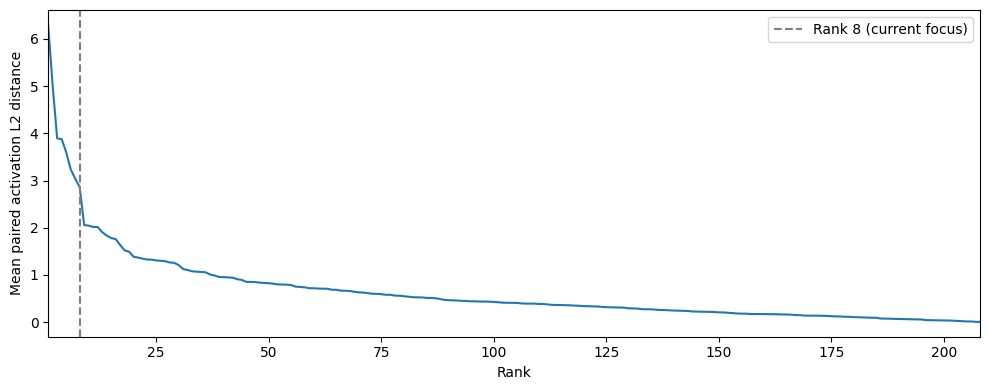

In [35]:
#@title Cell 28: Rank–score plot for all 208 heads
import numpy as np
import matplotlib.pyplot as plt

assert "original_head_scores" in globals() and original_head_scores.shape == (208,), "Run Cell 27 in this kernel first."
original_head_order = np.argsort(-original_head_scores, kind="stable")
sorted_original_scores = original_head_scores[original_head_order]
head_ranks = np.arange(1, 209)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(head_ranks, sorted_original_scores)
ax.axvline(8, linestyle="--", color="gray", label="Rank 8 (current focus)")
ax.set(xlabel="Rank", ylabel="Mean paired activation L2 distance", xlim=(1, 208))
ax.legend()
fig.tight_layout()
plt.show()


After rank 8: original gap = 0.806655; largest or tied largest in 0/1000 resamples (0.0%).
Every tied maximum counts. Frequencies may total above 100%; showing the 20 most frequent cutoffs.


,Original gap,Largest-gap / 1000,Largest-gap frequency
Cutoff after rank,,,
1,1.28939,692,69.2%
2,1.11475,308,30.8%
3,0.0170858,0,0.0%
4,0.273819,0,0.0%
5,0.361827,0,0.0%
6,0.199965,0,0.0%
7,0.176453,0,0.0%
8,0.806655,0,0.0%
9,0.0133371,0,0.0%


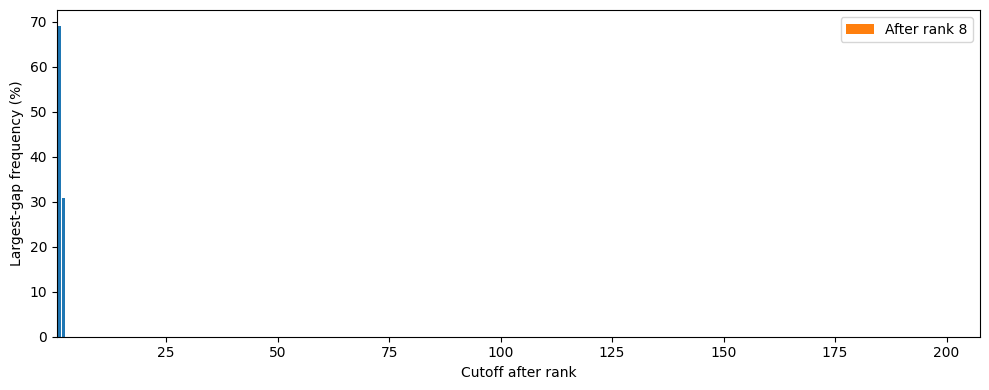

In [36]:
#@title Cell 29: Where are the largest adjacent-rank gaps?
assert "bootstrap_head_scores" in globals() and bootstrap_head_scores.shape == (1000, 208), "Run Cell 27 in this kernel first."
# Reuse Cell 27's scores and complete rankings; no new samples or model passes.
sorted_bootstrap_scores = np.take_along_axis(bootstrap_head_scores, bootstrap_head_order, axis=1)
bootstrap_rank_gaps = sorted_bootstrap_scores[:, :-1] - sorted_bootstrap_scores[:, 1:]
largest_gap_cutoffs = bootstrap_rank_gaps == bootstrap_rank_gaps.max(axis=1, keepdims=True)
cutoff_counts = largest_gap_cutoffs.sum(axis=0)
cutoff_frequencies = largest_gap_cutoffs.mean(axis=0)
original_rank_gaps = sorted_original_scores[:-1] - sorted_original_scores[1:]
gap_summary = pd.DataFrame({
    "Original gap": original_rank_gaps,
    "Largest-gap / 1000": cutoff_counts,
    "Largest-gap frequency": cutoff_frequencies,
}, index=np.arange(1, 208)).rename_axis("Cutoff after rank")

print(f"After rank 8: original gap = {original_rank_gaps[7]:.6g}; largest or tied largest in {cutoff_counts[7]}/1000 resamples ({cutoff_frequencies[7]:.1%}).")
print("Every tied maximum counts. Frequencies may total above 100%; showing the 20 most frequent cutoffs.")
display(gap_summary.sort_values("Largest-gap / 1000", ascending=False, kind="stable").head(20).style.format({
    "Original gap": "{:.6g}", "Largest-gap frequency": "{:.1%}",
}))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(gap_summary.index, 100 * cutoff_frequencies)
ax.bar(8, 100 * cutoff_frequencies[7], color="tab:orange", label="After rank 8")
ax.set(xlabel="Cutoff after rank", ylabel="Largest-gap frequency (%)", xlim=(0.5, 207.5))
ax.legend()
fig.tight_layout()
plt.show()


### Keeping the eighth and ninth heads fixed

Sorted gaps are always nonnegative, so a positive gap after rank 8 alone does not establish statistical significance. I'll separately keep the original eighth and ninth heads fixed and compare their scores in every existing bootstrap sample. Their signed difference can turn negative if those two heads reverse order.

These heads were selected from the same pairs used here, which introduces selection bias. The interval below is exploratory; held-out prompts would provide stronger confirmation. It does not automatically establish eight as the cutoff.


Original rank 8: layer 16, head 4; original rank 9: layer 25, head 7.
Original score difference (8th − 9th): 0.806655
95% percentile interval: [0.565452, 1.0533]


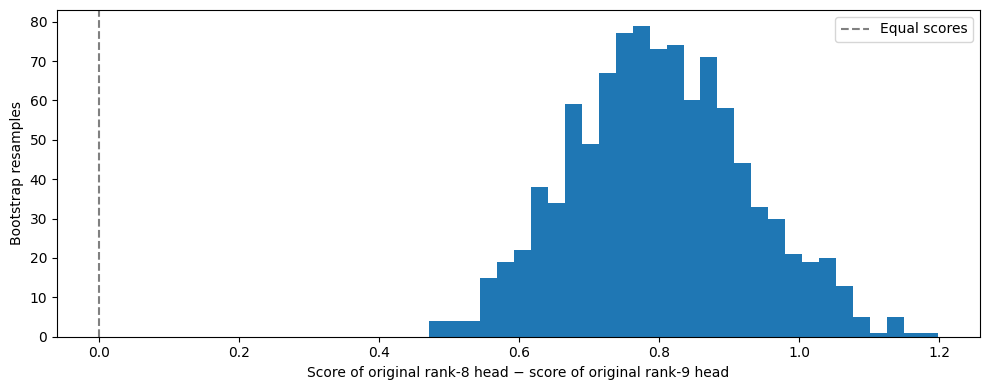

In [37]:
#@title Cell 30: Fixed original rank-8 versus rank-9 head difference
fixed_head8, fixed_head9 = original_head_order[7:9]
fixed_head_difference = bootstrap_head_scores[:, fixed_head8] - bootstrap_head_scores[:, fixed_head9]
fixed_difference_interval = np.percentile(fixed_head_difference, [2.5, 97.5], method="linear")
original_fixed_difference = original_head_scores[fixed_head8] - original_head_scores[fixed_head9]

print(f"Original rank 8: layer {fixed_head8 // 8}, head {fixed_head8 % 8}; original rank 9: layer {fixed_head9 // 8}, head {fixed_head9 % 8}.")
print(f"Original score difference (8th − 9th): {original_fixed_difference:.6g}")
print(f"95% percentile interval: [{fixed_difference_interval[0]:.6g}, {fixed_difference_interval[1]:.6g}]")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(fixed_head_difference, bins=30)
ax.axvline(0, linestyle="--", color="gray", label="Equal scores")
ax.set(xlabel="Score of original rank-8 head − score of original rank-9 head", ylabel="Bootstrap resamples")
ax.legend()
fig.tight_layout()
plt.show()
